> **Updated decision: threshold 0.37.** The original study below documents the historical 0.50 pipeline and its baseline results. The final section evaluates the newly selected 0.37 decision cutoff. The supplied training script uses 0.37. The original model artifact is preserved at 0.50; its trees and probability predictions are unchanged.

# Cardiovascular Disease Classification
### A reproducible study of data preparation, model selection and evaluation

**Prepared by Abdallah Mestrah**

**Machine Learning Project · Patient’s Sickness Prediction**

This project predicts the **presence or absence of cardiovascular disease** from measurements recorded at a medical examination. It compares classification models, investigates outlier handling, and examines the trade-off between missed disease cases and false alarms.

**Selected approach:** histogram gradient boosting with training-derived IQR clipping and a decision threshold of **0.50**.

| Final recorded test metric | Result |
|:--|--:|
| Accuracy | **73.85%** |
| ROC-AUC | **0.8051** |
| Disease recall | **69.66%** |
| No-disease recall | **77.87%** |

These scores describe the supplied dataset and pressure-valid records. They do not establish clinical suitability or predict future disease onset.

## 1. Objective and scope

The assignment asks for a model that checks whether a patient has cardiovascular disease using `cardio.csv`. The target is `cardio`: **0 = no disease, 1 = disease**. This is a supervised binary classification problem.

The dataset was supplied for the course. Its original collection process, patient identity structure and detailed label-generation procedure were not independently verified. No external records or additional labels are introduced.

### How to read and run this report

Read the saved tables and figures in order. The notebook loads a **copied, already trained model** by default. Setting `RETRAIN_MODEL = True` reproduces the selected training procedure and saves the new model **inside this report folder**. Neither mode writes to the original `final_evaluation` or model-backup folders.

Keep this notebook and its `assets` directory together. The assets include the dataset, model and frozen experiment results, so the report can be run without the original experiment directories. Historical tuning tables are reproduced from saved evidence; this report does not rerun every search.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import joblib
import sklearn
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, roc_auc_score, f1_score,
    recall_score, precision_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_curve,
)

RETRAIN_MODEL = False
current = Path.cwd()
report_dir = next((candidate for parent in [current, *current.parents]
                   for candidate in [parent, parent / "cardio" / "report"]
                   if (candidate / "assets" / "source_manifest.json").is_file()), None)
if report_dir is None:
    raise FileNotFoundError("Keep the notebook with its assets folder and run from this report or the project.")
assets = report_dir / "assets"
outputs = report_dir / "outputs"
outputs.mkdir(exist_ok=True)
source_manifest = json.loads((assets / "source_manifest.json").read_text(encoding="utf-8"))
for item in source_manifest:
    assert hashlib.sha256((assets / item["path"]).read_bytes()).hexdigest() == item["sha256"], item["path"]

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 170, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlepad": 12})
TEAL, BLUE, GREY, ORANGE = "#087f8c", "#355c9a", "#6b7280", "#c46b21"
def show_table(frame, formats=None, caption=None):
    style = frame.style.format(formats or {}, na_rep="—").set_properties(**{
        "padding": "7px 11px", "font-size": "13px", "text-align": "left"})
    style = style.set_table_styles([{"selector": "th", "props": [("background-color", "#eef5f6"),
        ("color", "#17313b"), ("padding", "8px 11px"), ("text-align", "left")]}])
    if caption:
        style = style.set_caption(caption)
    display(style)

print(f"Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print(f"Verified {len(source_manifest)} copied evidence files. Retrain selected model: {RETRAIN_MODEL}")

# Frozen summary tables embedded for a submission without experiment folders.
def read_asset_csv(path, *args, **kwargs):
    import io
    summaries = {'experiments/clip_outliers/comparison_results.csv': 'Model,Version,Accuracy,Balanced accuracy,ROC-AUC,Macro F1,Disease recall,No-disease recall,Disease precision\nHistogram gradient boosting,Clip outlier values,0.7343346163113144,0.7339984044712565,0.7988635815663633,0.7337062579367428,0.6912135573937965,0.7767832515487166,0.7529927494649238\nHistogram gradient boosting,Delete outlier rows,0.732716257612138,0.7323901396168644,0.7979087357199219,0.7321167533900633,0.6908837595662597,0.7738965196674691,0.7505085181463722\nHistogram gradient boosting,Keep outliers,0.7344255634276198,0.7340879127784538,0.7988389195244576,0.7337927359868146,0.6911036807630115,0.7770721447938961,0.7531949739183503\nLogistic regression,Clip outlier values,0.7284976856746438,0.7280293255558996,0.7908017087626201,0.7273300125121649,0.668413891168329,0.78764475994347,0.7560209155200737\nLogistic regression,Delete outlier rows,0.7288068063388063,0.7283194552998962,0.790589522831965,0.7275527330379317,0.6662878720704716,0.790351038529321,0.7577908716097191\nLogistic regression,Keep outliers,0.7193693880253393,0.719020797407951,0.7804708759955553,0.7186495432379751,0.6746820449614878,0.7633595498544141,0.7374323512983879\n', 'experiments/error_analysis/measurement_flag_errors.csv': 'Flag,Flagged,Samples,Errors,Error rate,Disease prevalence,Disease recall,No-disease recall,TN,FP,FN,TP,Small group\nheight,False,54590,14497,0.26556145814251697,0.49575013738779994,0.6887263052876621,0.7793802448505104,21454,6073,8424,18639,False\nheight,True,404,117,0.2896039603960396,0.5396039603960396,0.6788990825688074,0.7473118279569892,139,47,70,148,False\nweight,False,53595,14251,0.2659016699318966,0.49095997760985166,0.6820582981796071,0.7842900080639249,21397,5885,8366,17947,False\nweight,True,1399,363,0.2594710507505361,0.6919228020014296,0.8677685950413223,0.4547563805104408,196,235,128,840,False\nap_hi,False,54155,14489,0.2675468562459607,0.49127504385559967,0.6810749859049051,0.7820689655172414,21546,6004,8485,18120,False\nap_hi,True,839,125,0.14898688915375446,0.8057210965435042,0.9866863905325444,0.2883435582822086,47,116,9,667,False\nap_lo,False,52196,14029,0.26877538508697985,0.5032186374434823,0.6921495469428158,0.7708060161974547,19987,5943,8086,18180,False\nap_lo,True,2798,585,0.20907791279485347,0.362759113652609,0.5980295566502463,0.9007291082445317,1606,177,408,607,False\nAny IQR flag,False,50044,13515,0.2700623451362801,0.49448485332907044,0.680796896468116,0.7780061664953751,19682,5616,7899,16847,False\nAny IQR flag,True,4950,1099,0.222020202020202,0.5121212121212121,0.7652859960552268,0.7913043478260869,1911,504,595,1940,False\n', 'experiments/error_analysis/subgroup_errors.csv': 'Dimension,Group,Samples,Errors,Error rate,Disease prevalence,Disease recall,No-disease recall,TN,FP,FN,TP,Small group\nAge group,"[0.0, 40.0)",1477,218,0.14759647935003387,0.23696682464454977,0.5342857142857143,0.9511978704525288,1072,55,163,187,False\nAge group,"[40.0, 45.0)",6559,1149,0.1751791431620674,0.30690654063119377,0.568802781917536,0.9381874175098988,4265,281,868,1145,False\nAge group,"[45.0, 50.0)",8982,2151,0.23947895791583165,0.43041638833222,0.5957061562338334,0.8850664581704457,4528,588,1563,2303,False\nAge group,"[50.0, 55.0)",13482,3638,0.2698412698412698,0.46194926568758343,0.5979447655748233,0.8436724565756824,6120,1134,2504,3724,False\nAge group,"[55.0, 60.0)",14448,4472,0.30952380952380953,0.563953488372093,0.6804123711340206,0.7034920634920635,4432,1868,2604,5544,False\nAge group,"[60.0, inf)",10046,2986,0.29723272944455503,0.6645431017320327,0.8813660874775314,0.3489614243323442,1176,2194,792,5884,False\nSystolic group,"[0.0, 100.0)",840,120,0.14285714285714285,0.14761904761904762,0.08064516129032258,0.9916201117318436,710,6,114,10,False\nSystolic group,"[100.0, 120.0)",9351,2129,0.2276761843653085,0.24147150037429152,0.16607617360496013,0.9653179190751445,6847,246,1883,375,False\nSystolic group,"[120.0, 140.0)",29995,9992,0.33312218703117186,0.41550258376396065,0.47877718045414425,0.8005932010038787,14036,3496,6496,5967,False\nSystolic group,"[140.0, 160.0)",11160,1867,0.16729390681003584,0.8327956989247312,0.9998924037013127,0.0,0,1866,1,9293,False\nSystolic group,"[160.0, 180.0)",2905,403,0.1387263339070568,0.8612736660929432,1.0,0.0,0,403,0,2502,False\nSystolic group,"[180.0, inf)",743,103,0.1386271870794078,0.8613728129205922,1.0,0.0,0,103,0,640,False\nDiastolic group,"[0.0, 60.0)",115,31,0.26956521739130435,0.391304347826087,0.5333333333333333,0.8571428571428571,60,10,21,24,False\nDiastolic group,"[60.0, 80.0)",11143,2730,0.244996859014628,0.28609889616799783,0.3180677540777917,0.9301068510370836,7399,556,2174,1014,False\nDiastolic group,"[80.0, 90.0)",28234,8637,0.3059077707728271,0.4269320677197705,0.506885681101709,0.8335599505562423,13487,2693,5944,6110,False\nDiastolic group,"[90.0, 100.0)",11692,2621,0.2241703729045501,0.7507697570988711,0.9611528822055138,0.2175703500343171,634,2280,341,8437,False\nDiastolic group,"[100.0, 120.0)",3625,563,0.1553103448275862,0.8449655172413794,0.9954293176624225,0.023131672597864767,13,549,14,3049,False\nDiastolic group,"[120.0, inf)",185,32,0.17297297297297298,0.827027027027027,1.0,0.0,0,32,0,153,False\ncholesterol,1,41274,11125,0.2695401463390997,0.4373455444105248,0.5954240762284638,0.8354217801317659,19401,3822,7303,10748,False\ncholesterol,2,7465,2054,0.2751507032819826,0.5975887474882786,0.7718000448329971,0.6551264980026631,1968,1036,1018,3443,False\ncholesterol,3,6255,1435,0.22941646682653877,0.7624300559552358,0.963724051163766,0.15074024226110364,224,1262,173,4596,False\n', 'experiments/learning_curve/learning_curve_summary.csv': 'Fraction,Training rows_mean,Training rows_std,Train accuracy_mean,Train accuracy_std,Validation accuracy_mean,Validation accuracy_std,Train ROC-AUC_mean,Train ROC-AUC_std,Validation ROC-AUC_mean,Validation ROC-AUC_std,Disease recall_mean,Disease recall_std,No-disease recall_mean,No-disease recall_std\n0.1,4400.0,1.9999999999999716,0.7684993831427983,0.007863669682214032,0.7275702674684787,0.002733352639112991,0.8527205494209713,0.007136849565645448,0.7916773187446791,0.0024967277997951817,0.6841033027073301,0.01800465490896541,0.770361576527803,0.015062546101849301\n0.25,10999.8,3.8340579025359465,0.7513412089052183,0.003594491120629773,0.7308979352898239,0.0019095521074929953,0.8275306649554007,0.0031911526740706357,0.7969313709867408,0.002647379518868055,0.6816472305204593,0.011367875406492284,0.7793819040052533,0.008236122951977353\n0.5,21999.4,2.0736441353329256,0.7433746756625277,0.0020418193904709683,0.7330799931703689,0.0023401519285435536,0.8157711859384291,0.0017217968071043847,0.7991013928842187,0.0024619093319453653,0.6843959868596766,0.006496633604414201,0.7810052675018114,0.002226556971570266\n0.75,32998.4,2.3021728866445046,0.7398721695412417,0.001609065650712715,0.7335527568088362,0.0015044971436396386,0.8104272294024313,0.0007062514187217823,0.799659371415441,0.0025183299421969035,0.6903341009986367,0.0056457220004519,0.7760978193973523,0.004901900091976207\n1.0,43995.2,0.447213595500263,0.739303380967353,0.0006123286238567771,0.7342619088799109,0.0029719544274920853,0.8087161114110554,0.0005368954965003257,0.8003457609753253,0.00260261160424878,0.6886479645987263,0.005963811914942432,0.7791649394683591,0.0018813332537151812\n', 'experiments/split_stability/stability_summary.csv': ',Original five-fold mean,New repeat mean,New repeat minimum,New repeat maximum,New repeat standard deviation\nAccuracy,0.7342619088799109,0.7342301105387401,0.7337345766409917,0.7344984213132768,0.00034034018564401124\nBalanced accuracy,0.7339064520335427,0.7338726300419658,0.7333811347025208,0.734146487516523,0.0003387444704642239\nROC-AUC,0.8003457609753253,0.8001704239018705,0.7998599711785725,0.8003551637688666,0.00021918529406022438\nMacro F1,0.7335653974411569,0.7335268488871683,0.7330457467952063,0.7338128336198373,0.00033472928120578254\nDisease recall,0.6886479645987263,0.6883728061619583,0.687804674724331,0.6893806389275363,0.000718470278232127\nNo-disease recall,0.7791649394683591,0.7793724539219734,0.7783711650256683,0.7802476071562293,0.0008801276769855824\nDisease precision,0.754281062914206,0.754401076032008,0.7535568577299094,0.7549702837825262,0.00063411784267769\n', 'experiments/split_stability/validation_folds.csv': 'Split seed,Fold,Training rows,Validation rows,Accuracy,Balanced accuracy,ROC-AUC,Macro F1,Disease recall,No-disease recall,Disease precision\n42,1,43996,10998,0.7336788507001273,0.7333404614297008,0.800020898132205,0.7330376409300081,0.6900659824046921,0.7766149404547095,0.7525484709174496\n42,2,43995,10999,0.7309755432312028,0.7305883308741098,0.7963580224298116,0.7301672270461008,0.6816348973607038,0.7795417643875158,0.7526816433920259\n42,3,43995,10999,0.7372488408037094,0.7368943842409359,0.8012811262838178,0.7365732809872849,0.6920821114369502,0.7817066570449215,0.7573204973926996\n42,4,43995,10999,0.7319756341485589,0.7316040859322916,0.8005328824211229,0.7311995683946576,0.683525746747297,0.7796824251172861,0.7533831549181983\n42,5,43995,10999,0.737430675515956,0.7371049976906754,0.8035358756096695,0.7368492698477331,0.6959310850439883,0.7782789103373624,0.7554715479506566\n7,1,43996,10998,0.7324968176032006,0.7321448461812805,0.8003577684829576,0.7318064358267388,0.687133431085044,0.7771562612775171,0.752207062600321\n7,2,43995,10999,0.7386126011455587,0.738244565415787,0.8046073936480611,0.737893788222549,0.6917155425219942,0.7847735883095797,0.7598147775317092\n7,3,43995,10999,0.7316119647240659,0.7312474212780118,0.7969470742255964,0.7308609948703768,0.684075499358622,0.7784193431974017,0.7524692602297924\n7,4,43995,10999,0.7309755432312028,0.7306616876428118,0.7967001060226022,0.7304184552844539,0.6909824046920822,0.7703409705935415,0.7475708903430498\n7,5,43995,10999,0.7377943449404492,0.7373852645248056,0.8028213373661425,0.7369230125149913,0.6856671554252199,0.7891033736243911,0.7619144602851324\n21,1,43995,10999,0.7353395763251205,0.7349727741734443,0.8014711561912914,0.7346168218799194,0.688599706744868,0.7813458416020206,0.7560877440128798\n21,2,43996,10998,0.7406801236588471,0.7403371851952194,0.8046606042791331,0.7400394079498558,0.6964809384164223,0.7841934319740166,0.7606084867894315\n21,3,43995,10999,0.7320665515046823,0.7317110515071981,0.7954450059333507,0.7313751853380981,0.686766862170088,0.7766552408443081,0.7516549648946841\n21,4,43995,10999,0.7304300390944631,0.7300255321895519,0.7964203847763395,0.7295540013413649,0.6788856304985337,0.7811654338805701,0.753304860687411\n21,5,43995,10999,0.7339758159832712,0.7336858945172015,0.8013027047127481,0.733478751589948,0.6961700568077699,0.771201732226633,0.7497533057035721\n84,1,43995,10999,0.7335212292026548,0.7331471214387331,0.8003634970899335,0.7327678597961843,0.6858504398826979,0.7804438029947681,0.754587618471466\n84,2,43996,10998,0.7330423713402436,0.7326989658285278,0.8001807842220061,0.7323827846215906,0.6887829912023461,0.7766149404547095,0.7522017614091273\n84,3,43995,10999,0.7331575597781617,0.7327834292598046,0.8005648024799978,0.7324031622319348,0.6854838709677419,0.7800829875518672,0.7541843113530954\n84,4,43995,10999,0.7331575597781617,0.7328280186682312,0.7981022999074684,0.732555182212591,0.6911656891495601,0.7744903481869024,0.7510456084445329\n84,5,43995,10999,0.7357941631057369,0.7354481383173073,0.8016877398554507,0.7351197451137307,0.6906725306945208,0.7802237459400938,0.7557649889713255\n123,1,43995,10999,0.7357032457496137,0.7353479732964829,0.8035081002273349,0.7350212635825759,0.6904325513196481,0.7802633952733177,0.755667001003009\n123,2,43996,10998,0.7334969994544462,0.7331529106974096,0.7984325375617386,0.732836115860694,0.6891495601173021,0.7771562612775171,0.7527527527527528\n123,3,43995,10999,0.7372488408037094,0.7368747969344265,0.8064504273329618,0.7364776800260671,0.6884735202492211,0.7852760736196319,0.7594501718213058\n123,4,43995,10999,0.7359759978179835,0.7356185848786586,0.8005451943827067,0.7352873550263179,0.6904325513196481,0.7808046184376691,0.7561220393416299\n123,5,43995,10999,0.7295208655332303,0.7291364388944234,0.7928395593395913,0.7287189744533837,0.6805351906158358,0.777737687173011,0.7508594539939333\n', 'experiments/threshold_048_stability/test_comparison.csv': 'Threshold,Accuracy,Balanced accuracy,ROC-AUC,Macro F1,Disease recall,No-disease recall,Disease precision,No-disease precision,TN,FP,FN,TP\n0.5,0.7385074192609834,0.7376712271921853,0.8050627604733678,0.7376824132411668,0.6966141966141967,0.778728257770174,0.7514015697581291,0.7277814790139907,5462,1552,2043,4691\n0.48,0.7349432644748327,0.734477584776986,0.8050627604733678,0.7345635228142529,0.7116127116127117,0.7573424579412603,0.7379119186941793,0.732285635511442,5312,1702,1942,4792\n', 'experiments/threshold_comparison/threshold_summary.csv': 'Threshold,Accuracy,Balanced accuracy,ROC-AUC,Macro F1,Disease recall,No-disease recall,Disease precision,No-disease precision,Recall gap\n0.2,0.5952467384452497,0.5981303186423458,0.8003457609753253,0.5340549126148186,0.9652139332999076,0.23104670398478402,0.5527061190947677,0.8709635566460785,0.7341672293151236\n0.21,0.6027929881241498,0.6055757744966211,0.8003457609753253,0.547517429552632,0.9598255717722723,0.2513259772209698,0.5579261248003367,0.864036455564251,0.7084995945513026\n0.22,0.6093027782899009,0.6119807493826734,0.8003457609753253,0.5595342900648067,0.9528976342366364,0.2710638645287104,0.5627247252734685,0.8539403449832174,0.681833769707926\n0.23,0.6170491023659493,0.6196194911581518,0.8003457609753253,0.5726231608989207,0.9468494016402296,0.29238958067607385,0.568459261647123,0.8481954426494582,0.6544598209641557\n0.24,0.6269229388688992,0.6293471769553729,0.8003457609753253,0.5889882915483521,0.9379787361816214,0.3207156177291245,0.5761639017938002,0.8401017769902062,0.6172631184524969\n0.25,0.6393060696006998,0.6415430625836308,0.8003457609753253,0.6086706703806468,0.926322375361195,0.3567637498060666,0.5863816641077263,0.8311130334294482,0.5695586255551284\n0.26,0.649161644925283,0.651244706073401,0.8003457609753253,0.6236983531774337,0.9164253975495973,0.3860640145972048,0.5950580794934925,0.8243761028177709,0.5303613829523925\n0.27,0.6577080533086205,0.6596453188714617,0.8003457609753253,0.6364810011421149,0.9062718214975304,0.413018816245393,0.6031852708591382,0.8175188395152896,0.4932530052521374\n0.28,0.6657452649773035,0.6675373875194085,0.8003457609753253,0.6482397271373983,0.8956784097693673,0.4393963652694498,0.6113454126167343,0.8106356504276346,0.4562820444999175\n0.29,0.6737643444284087,0.6754211625038239,0.8003457609753253,0.6593395163015308,0.8863312517431672,0.4645110732644806,0.6197067212053093,0.8059525049340431,0.4218201784786866\n0.3,0.6802013957492308,0.681722244102816,0.8003457609753253,0.6684270323650502,0.8753345940563305,0.4881098941493014,0.6273568037291447,0.7991786772193887,0.3872246999070291\n0.31,0.6865475627807986,0.6879498830717939,0.8003457609753253,0.6768509977223147,0.8664639084455006,0.5094358576980873,0.6348825462689445,0.7949351421753452,0.3570280507474133\n0.32,0.6910026041647293,0.6923159246924231,0.8003457609753253,0.6826905855148021,0.8594993610402201,0.525132488344626,0.6405312405379302,0.7915560352041366,0.33436687269559406\n0.33,0.6950212174391162,0.6962526719917713,0.8003457609753253,0.6878655420862784,0.8530113397895678,0.539494004193975,0.6458422197379742,0.7885465977877898,0.3135173355955928\n0.34,0.6997854009806741,0.7009275210575583,0.8003457609753253,0.6937841080338205,0.8463033704725348,0.5555516716425821,0.6521307888207255,0.7859741427770927,0.29075169882995267\n0.35,0.7046222605401099,0.7056538229878061,0.8003457609753253,0.6998649997733901,0.8369562527507783,0.5743513932248339,0.6593835508125009,0.781599923662197,0.2626048595259445\n0.36,0.7094773234108918,0.7103662826460997,0.8003457609753253,0.7060541609647807,0.8235402133556029,0.5971923519365965,0.6681080070357699,0.774721080346382,0.22634786141900642\n0.37,0.7132959019683731,0.7140637443907581,0.8003457609753253,0.7108192729742806,0.8118105185999633,0.616316970181553,0.6756826373035473,0.7689201536366028,0.19549354841841038\n0.38,0.7170963383882161,0.7177513167127021,0.8003457609753253,0.7153617894795931,0.801143719197329,0.6343589142280753,0.6832701760016217,0.764218810371642,0.16678480496925363\n0.39,0.720951348368541,0.7214957961441055,0.8003457609753253,0.7198108736859485,0.7908068586877841,0.6521847336004271,0.691199461877267,0.7600411191071507,0.13862212508735705\n0.4,0.724224412869222,0.7246759074151,0.8003457609753253,0.7234745147843976,0.7821562017522223,0.6671956130779777,0.6982343094020584,0.7567890104360788,0.11496058867424463\n0.41,0.726042779831809,0.7263879769904756,0.8003457609753253,0.7256295557098131,0.7703529916913733,0.6824229622895778,0.7048701306044742,0.7511950866501327,0.0879300294017955\n0.42,0.7290794691266301,0.7293194060821468,0.8003457609753253,0.7289056042297748,0.7598695170506605,0.6987692951136332,0.712937517596216,0.7472360098628911,0.061100221937027355\n0.43,0.7295522377251278,0.7297150935418133,0.8003457609753253,0.7294833477133879,0.7504490922633202,0.7089810948203061,0.7174297032232944,0.742681517568683,0.041467997443014104\n0.44,0.7315161071777243,0.7316062056181721,0.8003457609753253,0.7315029399779596,0.7430812988993662,0.720131112336978,0.7232940227766009,0.7400914849724808,0.02295018656238823\n0.45,0.7321161633814814,0.7321487452677272,0.8003457609753253,0.7321126575881375,0.7363000090819346,0.7279974814535198,0.727145821846374,0.737152051975243,0.008302527628414769\n0.46,0.7327889964570669,0.7327511661403983,0.8003457609753253,0.7327580553855115,0.7279424863650068,0.7375598459157898,0.7319477634116989,0.7336159192500757,0.009617359550783022\n0.47,0.7328799534934329,0.732765212107149,0.8003457609753253,0.7327680551777872,0.7181555128149322,0.7473749113993656,0.7367422761837152,0.7292713206346356,0.029219398584433454\n0.48,0.7339528163225869,0.7337640477327115,0.8003457609753253,0.7337153017309717,0.7097248039457513,0.7578032915196717,0.7425813748208099,0.7261799326906284,0.048078487573920414\n0.49,0.7340619105365611,0.7337934437714919,0.8003457609753253,0.7336356035342811,0.6996078713503655,0.7679790161926184,0.7480028338265158,0.7220017518142492,0.06837114484225293\n0.5,0.7342619088799109,0.7339064520335427,0.8003457609753253,0.7335653974411569,0.6886479645987263,0.7791649394683591,0.754281062914206,0.7177019710677592,0.09051697486963273\n0.51,0.7340436857317503,0.7336095936996994,0.8003457609753253,0.7330477622654961,0.6783477005240115,0.7888714868753871,0.7597826607457208,0.713589248657243,0.11052378635137561\n0.52,0.7336800113472267,0.7331689546178335,0.8003457609753253,0.7323367786044386,0.6681207099278443,0.7982171993078229,0.7652377804001473,0.709577018440964,0.13009648937997853\n0.53,0.7332072477087594,0.7326235627736655,0.8003457609753253,0.7314845248069041,0.6583336490514752,0.8069134764958557,0.7704595821578566,0.7058106377146506,0.14857982744438047\n0.54,0.7330981551481287,0.7324465243777218,0.8003457609753253,0.7309803134897216,0.6494996606365845,0.8153933881188593,0.7759550613285647,0.7026701823509065,0.16589372748227482\n0.55,0.7325526477047022,0.7318375568172829,0.8003457609753253,0.7300231682997176,0.6408122729180471,0.8228628407165187,0.7807556953225943,0.6994495784032113,0.18205056779847162\n0.56,0.7317161782681859,0.7309281728234084,0.8003457609753253,0.728663549756216,0.6306220332570773,0.8312343123897395,0.7862529951099746,0.6956819947122277,0.20061227913266222\n0.57,0.7308615137870409,0.729984438761486,0.8003457609753253,0.7271001140689182,0.6183423642156728,0.8416265133072993,0.7935356767306307,0.6913730005949013,0.22328414909162653\n0.58,0.729188603020847,0.7282385698871703,0.8003457609753253,0.7247716157047576,0.6073090563547479,0.8491680834195929,0.7985401643296933,0.6871803233862881,0.24185902706484508\n0.59,0.7270974806832031,0.7260751349208678,0.8003457609753253,0.7219647126359392,0.595945823035548,0.8562044468061876,0.8031554112418229,0.6828056702599044,0.2602586237706396\n0.6,0.7247881517308332,0.7236937784176876,0.8003457609753253,0.7188758350462793,0.584399278389241,0.8629882784461342,0.807665564552601,0.6783968967276247,0.27858900005689324\n0.61,0.723551659154122,0.7224043283404721,0.8003457609753253,0.7170354967336575,0.5763716744131807,0.8684369822677634,0.8117877088310668,0.6755901129335731,0.29206530785458273\n0.62,0.7219151219437513,0.7207131267363411,0.8003457609753253,0.7147312634643966,0.5677209099991025,0.8737053434735798,0.815680333853796,0.6724775695513807,0.30598443347447724\n0.63,0.7203695153162513,0.7191209650788869,0.8003457609753253,0.7125810519151047,0.5602064823517588,0.8780354478060148,0.8189006568576047,0.6697676776970537,0.317828965454256\n0.64,0.7185329252021969,0.7172370064994381,0.8003457609753253,0.7100934508997477,0.5522888490501854,0.8821851639486908,0.8219007589283299,0.6668552017465484,0.32989631489850546\n0.65,0.7168963846851393,0.715560058777857,0.8003457609753253,0.7078737050458368,0.5454709560805164,0.8856491614751973,0.8244556406780083,0.6643613724273019,0.3401782053946809\n0.66,0.715350784671013,0.7139770635088865,0.8003457609753253,0.7057646606870508,0.5391295422436247,0.8888245847741482,0.826818188820296,0.6620684035625267,0.3496950425305234\n0.67,0.7139688177111309,0.7125624829488648,0.8003457609753253,0.7038733287009509,0.533557929845548,0.8915670360521816,0.8288828869717519,0.660066393081723,0.3580091062066336\n0.68,0.7128596143930227,0.7114245320194382,0.8003457609753253,0.7023058484566715,0.5287560920166571,0.8940929720222195,0.830930919012107,0.6583997245277671,0.3653368800055624\n0.69,0.7119140722359971,0.7104572311513492,0.8003457609753253,0.7010004088479785,0.5250172503018803,0.8958972120008181,0.8323373975432913,0.6570751282418803,0.3708799616989378\n0.7,0.71064121437018,0.7091617280250067,0.8003457609753253,0.6993340707344132,0.5208385258891564,0.8974849301608572,0.8333630910145556,0.6554989263435514,0.3766464042717008\n0.71,0.7093865284021836,0.7078862400123809,0.8003457609753253,0.6977071491247147,0.5169163795646797,0.898856100460082,0.8341842918575819,0.6540006894206184,0.3819397208954023\n0.72,0.7079136490462086,0.7063879764402617,0.8003457609753253,0.6957703362095586,0.5121877950621145,0.9005881578184092,0.8352925035053612,0.6522320425887533,0.38840036275629464\n0.73,0.7064407515034554,0.7048908941011518,0.8003457609753253,0.6938433206713335,0.507605918734419,0.9021758694678844,0.8362717273105235,0.6505062841201392,0.39456995073346546\n0.74,0.7047678473506354,0.7031887994806234,0.8003457609753253,0.6916096992527525,0.5021809742067683,0.9041966247544785,0.8376483083341812,0.6485222591144979,0.40201565054771016\n0.75,0.7024221531091595,0.7008130992881698,0.8003457609753253,0.6886439155785868,0.49598620137067356,0.905639997205666,0.838027549170608,0.6460630347511531,0.40965379583499245\n0.76,0.700185546468284,0.6985433555677354,0.8003457609753253,0.6857168801538707,0.4894981868374286,0.9075885242980425,0.8390719469383026,0.6436256910933055,0.4180903374606139\n0.77,0.6976398075898417,0.6959623093292058,0.8003457609753253,0.6824029148179805,0.48242365532284665,0.909500963335565,0.8399346770354225,0.6409463157922687,0.4270773080127183\n0.78,0.694694032344457,0.692974618270919,0.8003457609753253,0.6785145277359161,0.47410282308445073,0.9118464134573874,0.8411320987230244,0.6378613150925873,0.43774359037293664\n0.79,0.6892752504521853,0.6874840788011987,0.8003457609753253,0.6713657611254374,0.4594772607702877,0.9154908968321094,0.8426238726875404,0.632429705131711,0.45601363606182166\n0.8,0.6791832387480348,0.6772668333641629,0.8003457609753253,0.6579162900030833,0.4333053486146288,0.921228318113697,0.8441556861132969,0.622843022235699,0.48792296949906816\n', 'experiments/tuned_outlier_comparison/comparison_results.csv': 'Treatment,Train accuracy_mean,Train accuracy_std,Train ROC-AUC_mean,Train ROC-AUC_std,Accuracy_mean,Accuracy_std,Balanced accuracy_mean,Balanced accuracy_std,ROC-AUC_mean,ROC-AUC_std,Macro F1_mean,Macro F1_std,Disease recall_mean,Disease recall_std,No-disease recall_mean,No-disease recall_std,Disease precision_mean,Disease precision_std,ROC-AUC change vs IQR\nIQR clipping,0.739303380967353,0.0006123286238567771,0.8087161114110554,0.0005368954965003257,0.7342619088799109,0.0029719544274920853,0.7339064520335427,0.002991220330117954,0.8003457609753253,0.00260261160424878,0.7335653974411569,0.0030518198446130435,0.6886479645987263,0.005963811914942432,0.7791649394683591,0.0018813332537151812,0.754281062914206,0.002062866523524841,0.0\nPercentile 1-99 clipping,0.7392170098923436,0.0007362200705689553,0.8086956202292125,0.0005050618927200418,0.734007330362705,0.0026779267272125907,0.733651553378748,0.002702127790348415,0.8002545753749363,0.0025170802798771216,0.7333078201342657,0.002773505704750953,0.6883546825971324,0.006441743563364353,0.7789484241603635,0.002461323679112217,0.7540245856336518,0.0017511051549933064,-9.118560038900991e-05\nNo clipping,0.7392806514216683,0.00046967222787701687,0.8088057595969719,0.00045540552913708065,0.733916406393208,0.002697000365419358,0.7335616010732595,0.0027135311324910493,0.8001365114515746,0.002407958628617454,0.7332218479273299,0.002766422300967109,0.6883913193364062,0.005423484261176771,0.778731882810113,0.002023919337441183,0.7538506981496962,0.0020003536712495176,-0.0002092495237506764\n', 'experiments/tune_catboost/tuning_results.csv': 'Candidate,iterations,learning_rate,depth,Accuracy_mean,Accuracy_std,Balanced accuracy_mean,Balanced accuracy_std,ROC-AUC_mean,ROC-AUC_std,Macro F1_mean,Macro F1_std,Disease recall_mean,Disease recall_std,No-disease recall_mean,No-disease recall_std,Disease precision_mean,Disease precision_std\n11,300,0.03,6,0.7333163650695418,0.0017212484125459226,0.732952122640198,0.0017185821194935292,0.8002160715834499,0.0027088165848208772,0.7325895377016587,0.0017213296046445627,0.6865950577616416,0.0022310785984071655,0.7793091875187546,0.0024435705296527994,0.7538566224450192,0.002165567043139164\n8,100,0.1,6,0.7329344873736724,0.0014460324123964652,0.732566621048439,0.0014399764681851772,0.8001039719369857,0.002613549243310334,0.7321926357882743,0.0014386691180186,0.6857519761268719,0.0030092764751558404,0.7793812659700059,0.003375206680917671,0.7536956115066205,0.0024116584630109266\n6,300,0.1,4,0.7342073749996715,0.0014453577432963485,0.7338761107920009,0.0014412468990139995,0.8000269091205388,0.0029433700088246726,0.7335938795199599,0.0014382984283514777,0.6917267605921421,0.003101544032727958,0.7760254609918597,0.0034575994039609767,0.7525018845815181,0.00243022891685888\n4,200,0.1,4,0.7338436940017742,0.0015011772183828047,0.733516965430394,0.0014900576403196666,0.8000152431357336,0.003008440010281855,0.7332443639278958,0.0014717473002085117,0.6919466616366721,0.0025808638681800752,0.775087269224116,0.0037838770422149066,0.7517839415654908,0.002743750934275871\n9,200,0.03,6,0.7330435898543637,0.001838448207596089,0.7326652494045011,0.0018336282469560328,0.7999124882140515,0.0026581920789274325,0.7322649465778227,0.001833324232324162,0.6845057627293525,0.0020475222600721257,0.7808247360796496,0.0025525954125895085,0.7545692588506864,0.0023469685923167122\n10,200,0.1,6,0.7340982625989193,0.0016590870335961622,0.7337604096392758,0.0016490919869893898,0.7998464973511695,0.00284383328384314,0.7334631506164128,0.0016337085826562238,0.690773694848071,0.002656343742138704,0.7767471244304802,0.0038020741881572076,0.7528478607796666,0.002837992765616628\n5,300,0.03,4,0.7329345072137937,0.0014542819122497525,0.7325673309998406,0.001459491545459585,0.7995928268628516,0.0027285914400669445,0.7321958497689165,0.0014794662334710685,0.6858253638013432,0.0026125071825996225,0.7793092981983382,0.0015314747896016435,0.7536456646526164,0.0014137950986571053\n2,100,0.1,4,0.7328071948083825,0.0011331934325841812,0.7324427125242593,0.0011240714187133296,0.7993584504015601,0.002793558163247924,0.7320782780217543,0.0011098553855548963,0.6860452715632803,0.0008313687085557246,0.7788401534852383,0.002190611203072123,0.7533140346145955,0.0018142790317321209\n12,300,0.1,6,0.7329163419293471,0.002548726583918358,0.7325803106816176,0.002547205445568936,0.799294197218802,0.0027571665073124574,0.7322847933281356,0.0025502602429380954,0.6898207097128873,0.0035150870612301144,0.7753399116503478,0.0037207463384430176,0.7514147424403166,0.0032224715365252268\n3,200,0.03,4,0.732061692328293,0.001107720295208095,0.731668378074904,0.0011165720666292775,0.7989062989894263,0.0026177175400167625,0.7312222659717186,0.0011520424607215926,0.6816099489100872,0.00379975745850704,0.7817268072397209,0.002901982010192172,0.7545521212881693,0.0017143699138899109\n7,100,0.03,6,0.7310069980902726,0.0011713510152171235,0.7305472102817849,0.0011680992466791948,0.7973608867926844,0.002745528598230446,0.7298870481123952,0.0011739780389909535,0.6720427017519535,0.004869938477444475,0.7890517188116164,0.0050499858019916796,0.7582556958172657,0.003217793570430347\n1,100,0.03,4,0.7288795369170181,0.0017969131645424194,0.7283505004746084,0.0018200044234861312,0.7956495856226687,0.002661940904103151,0.7274175702780923,0.0019122967108412433,0.6610095618262105,0.006422939190720378,0.7956914391230062,0.0047690190401532,0.7610689429156094,0.002942137078698486\n', 'experiments/tune_gradient_boosting/tuning_results.csv': 'Candidate,max_iter,learning_rate,max_leaf_nodes,Accuracy_mean,Accuracy_std,Balanced accuracy_mean,Balanced accuracy_std,ROC-AUC_mean,ROC-AUC_std,Macro F1_mean,Macro F1_std,Disease recall_mean,Disease recall_std,No-disease recall_mean,No-disease recall_std,Disease precision_mean,Disease precision_std\n3,200,0.03,15,0.7342619088799109,0.0029719544274920853,0.7339064520335427,0.002991220330117954,0.8003457609753253,0.00260261160424878,0.7335653974411569,0.0030518198446130435,0.6886479645987263,0.005963811914942432,0.7791649394683591,0.0018813332537151812,0.754281062914206,0.002062866523524841\n5,300,0.03,15,0.7338800460641324,0.002919398224740212,0.7335346254607878,0.0029340639465422528,0.8000569526640241,0.002643027314935305,0.7332184754787793,0.0029790851830086584,0.6895642122335272,0.005110966143331564,0.7775050386880485,0.0017441441202806207,0.7531375407787614,0.0022716622471764696\n7,100,0.1,15,0.7341709832570704,0.0024312103261670192,0.7338289550711976,0.0024484184293483095,0.7996680067460422,0.002831325740276254,0.7335204903053048,0.0024975192875759016,0.6902972627371446,0.005343606513632972,0.7773606474052507,0.0025335690516414032,0.7532204001314984,0.0020009545405701066\n4,200,0.03,31,0.734225528710714,0.002126488543236067,0.7338859668345226,0.0021257330851154324,0.7995978960190676,0.0024664272342426216,0.7335861043940893,0.002131796406609713,0.6906638114998789,0.0022533656224028244,0.7771081221691662,0.0021791825296377,0.7531079189107268,0.0023386992248003754\n2,100,0.03,31,0.7336072609288936,0.0014037033368371182,0.7332634580630979,0.0013995969728744471,0.7994100984783792,0.0022648652540061816,0.7329518066937232,0.0013966979478120306,0.689490898450536,0.001551539681105859,0.7770360176756597,0.0021095549615596,0.7527336875774345,0.0018695956116687987\n1,100,0.03,15,0.7327708063724685,0.002565185102249466,0.7323964505697058,0.002570929547063734,0.7992709238166015,0.0024784745796833027,0.7320045030579833,0.0026015182550734872,0.6847258384264715,0.004212669390900534,0.7800670627129402,0.0026418708654096347,0.7539865445601462,0.002566952460356025\n6,300,0.03,31,0.7342073501995197,0.0020994393373513836,0.7338696221859264,0.00209983788203144,0.7991297771591108,0.0025622691706129594,0.7335738261586207,0.002107321338292757,0.6908837125444087,0.002512990400314358,0.7768555318274443,0.0022736591762658105,0.7529570152387475,0.002320058923739437\n9,200,0.1,15,0.7340436824250633,0.0019355589176530041,0.7337091954740474,0.0019520982190003567,0.7989906530650599,0.002770306258719331,0.7334192401103575,0.0019919766907196823,0.691140189871547,0.004254811693321274,0.7762782010765478,0.001524037580402904,0.7525430394553181,0.0013239526770152763\n8,100,0.1,31,0.7343346163113144,0.002676421918083607,0.7339984044712565,0.002669235496415613,0.7988635815663633,0.0025811545343988203,0.7337062579367428,0.00266068063615857,0.6912135573937965,0.002530619392129503,0.7767832515487166,0.0038914901656614633,0.7529927494649238,0.003533669122911139\n11,300,0.1,15,0.7337345931744262,0.0019772555891132576,0.7334025593421216,0.001992252397239531,0.7982337379779403,0.0028875411540019796,0.7331179872993053,0.002028509605446017,0.6911402973500633,0.003881473536609606,0.7756648213341799,0.000739168718644653,0.7520309031190983,0.0012391342037241836\n10,200,0.1,31,0.7330981286946336,0.0019521110070723094,0.7327561810413268,0.001950425149491652,0.7973592263202345,0.0025327556945030963,0.7324479895067364,0.001954760985972603,0.6892342196011795,0.002363876036516551,0.776278142481474,0.0024330683715820273,0.7520318722251405,0.0022967794188317324\n12,300,0.1,31,0.7323889617434679,0.002703798801944452,0.7320428801442656,0.002697976197948658,0.7956482074309157,0.002591886529098769,0.7317229393119173,0.0026917941241730915,0.6879879994862528,0.0025969332833380753,0.7760977608022785,0.003755051486289535,0.7515483695467204,0.0034815309466402185\n', 'experiments/tune_gradient_boosting/validation_folds.csv': 'Candidate,Fold,learning_rate,max_iter,max_leaf_nodes,Accuracy,Balanced accuracy,ROC-AUC,Macro F1,Disease recall,No-disease recall,Disease precision\n1,1,0.03,100,15,0.7304964539007093,0.7301344055154401,0.799383701877743,0.7297654739555606,0.6838343108504399,0.7764345001804402,0.7507042253521127\n1,2,0.03,100,15,0.7311573779434494,0.7307802455396704,0.7951718978733582,0.7303868483535046,0.6831011730205279,0.778459318058813,0.7521695257315842\n1,3,0.03,100,15,0.735521411037367,0.7351445516868123,0.8004446904843656,0.7347633891986287,0.6875,0.7827891033736244,0.7570131180625631\n1,4,0.03,100,15,0.7310664605873262,0.7306681574068765,0.7995762877473812,0.7301840667241875,0.6791277258566978,0.7822085889570553,0.754325259515571\n1,5,0.03,100,15,0.7356123283934903,0.7352548926997301,0.801778041100159,0.7349227370580346,0.6900659824046921,0.7804438029947681,0.7557205941389\n2,1,0.03,100,31,0.7313147845062739,0.7309748285817395,0.7990190842047559,0.7306630615501946,0.6875,0.7744496571634789,0.7500499900019996\n2,2,0.03,100,31,0.7335212292026548,0.7331845190070909,0.7959130211256913,0.7328963491165006,0.6906158357771262,0.7757532022370558,0.7519457194172819\n2,3,0.03,100,31,0.7350668242567506,0.734712231167365,0.800784294132305,0.7343856542549994,0.6898826979472141,0.7795417643875158,0.7549137585238668\n2,4,0.03,100,31,0.7338848986271479,0.7335352465623599,0.7994245155540707,0.7331932804274228,0.6882902693787796,0.7787802237459401,0.7539140907266159\n2,5,0.03,100,31,0.7342485680516411,0.7339104649969341,0.801909577375073,0.7336206881194987,0.6911656891495601,0.7766552408443081,0.7528448792174086\n3,1,0.03,200,15,0.7336788507001273,0.7333404614297008,0.800020898132205,0.7330376409300081,0.6900659824046921,0.7766149404547095,0.7525484709174496\n3,2,0.03,200,15,0.7309755432312028,0.7305883308741098,0.7963580224298116,0.7301672270461008,0.6816348973607038,0.7795417643875158,0.7526816433920259\n3,3,0.03,200,15,0.7372488408037094,0.7368943842409359,0.8012811262838178,0.7365732809872849,0.6920821114369502,0.7817066570449215,0.7573204973926996\n3,4,0.03,200,15,0.7319756341485589,0.7316040859322916,0.8005328824211229,0.7311995683946576,0.683525746747297,0.7796824251172861,0.7533831549181983\n3,5,0.03,200,15,0.737430675515956,0.7371049976906754,0.8035358756096695,0.7368492698477331,0.6959310850439883,0.7782789103373624,0.7554715479506566\n4,1,0.03,200,31,0.7329514457174031,0.732611589874602,0.7993741110273878,0.7323036926473507,0.6891495601173021,0.7760736196319018,0.7518496300739852\n4,2,0.03,200,31,0.7317028820801891,0.731357427904366,0.795801324409588,0.7310449651321429,0.6876832844574781,0.7750315713512538,0.7505501100220044\n4,3,0.03,200,31,0.7358850804618602,0.7355398879620435,0.8009719763586527,0.735237419081286,0.6918988269794721,0.7791809489446149,0.7551510302060412\n4,4,0.03,200,31,0.7337030639149014,0.73337729105747,0.7994244494223961,0.7330926483201405,0.6912222833058457,0.7755322988090942,0.751993620414673\n4,5,0.03,200,31,0.7368851713792163,0.7365436373741312,0.8024176188773138,0.7362517967895261,0.6933651026392962,0.7797221721089662,0.7559952038369304\n5,1,0.03,300,15,0.7331332969630842,0.732801984790102,0.7995443486211928,0.7325144486073858,0.6904325513196481,0.7751714182605558,0.7514462397765809\n5,2,0.03,300,15,0.7298845349577234,0.7295073229134207,0.7961025550441946,0.7291103572736768,0.6818181818181818,0.7771964640086596,0.7507568113017155\n5,3,0.03,300,15,0.7360669151741067,0.7357174189474665,0.8008925850574791,0.7354053081577843,0.6915322580645161,0.7799025798304168,0.7556579210895253\n5,4,0.03,300,15,0.7329757250659151,0.7326330451910137,0.8003314288072353,0.7323063692936316,0.6882902693787796,0.7769758210032479,0.7524038461538461\n5,5,0.03,300,15,0.7373397581598327,0.7370133554619364,0.8034138457900192,0.7367558940614182,0.6957478005865103,0.7782789103373624,0.7554228855721393\n6,1,0.03,300,31,0.7332242225859247,0.7328865165608189,0.7990613170182166,0.7325843050468994,0.6896994134897361,0.7760736196319018,0.7519984012789768\n6,2,0.03,300,31,0.7314301300118192,0.7310853779541764,0.7950909194074798,0.7307739691783987,0.6875,0.7746707559083529,0.7502\n6,3,0.03,300,31,0.735521411037367,0.7351704423110599,0.8004251319859715,0.7348535939976846,0.6907991202346041,0.7795417643875158,0.755159286716089\n6,4,0.03,300,31,0.7339758159832712,0.733656383257391,0.7990673714451498,0.7333867602404665,0.6923217885284955,0.7749909779862866,0.7518407960199005\n6,5,0.03,300,31,0.7368851713792163,0.7365493908461862,0.8020041459387366,0.7362705023296539,0.6940982404692082,0.7790005412231643,0.755586592178771\n7,1,0.1,100,15,0.7332242225859247,0.7329035816600717,0.7995983054224154,0.7326402468011748,0.6918988269794721,0.7739083363406712,0.7507955449482896\n7,2,0.1,100,15,0.7308846258750795,0.7305024421174258,0.7950558033883851,0.7300947864626847,0.6821847507331378,0.7788201335017139,0.7522231204527081\n7,3,0.1,100,15,0.735521411037367,0.7351618121029774,0.8007645372383229,0.7348241654922569,0.6896994134897361,0.7806242107162187,0.7557742518578028\n7,4,0.1,100,15,0.7338848986271479,0.7335535154374806,0.8002040096031127,0.7332561594682767,0.6906725306945208,0.7764345001804402,0.7525958466453674\n7,5,0.1,100,15,0.7373397581598327,0.7370234240380327,0.8027173780779753,0.7367870933021305,0.6970307917888563,0.777016056287209,0.754713236753324\n8,1,0.1,100,31,0.7322240407346791,0.731896939235547,0.7985501908380788,0.7316171217071907,0.6900659824046921,0.773727896066402,0.7501494321578004\n8,2,0.1,100,31,0.7312482952995727,0.7309064086007397,0.7950210676275009,0.7306013515237868,0.6876832844574781,0.7741295327440014,0.7498001598721024\n8,3,0.1,100,31,0.7359759978179835,0.7356243383507137,0.8001632828756038,0.7353069048418379,0.6911656891495601,0.7800829875518672,0.7557114228456914\n8,4,0.1,100,31,0.7344304027638876,0.7341215369239262,0.7985570167789946,0.7338760515682468,0.6941542972329119,0.7740887766149405,0.7515873015873016\n8,5,0.1,100,31,0.7377943449404492,0.737442799245356,0.8020263497116386,0.7371298600426517,0.6929985337243402,0.781887064766372,0.7577154308617234\n9,1,0.1,200,15,0.7323149663575196,0.7319757826398465,0.798636194308247,0.7316680733781273,0.688599706744868,0.775351858534825,0.7510995601759296\n9,2,0.1,200,15,0.7317028820801891,0.7313459209602557,0.7944383963182012,0.7310055929420309,0.6862170087976539,0.7764748331228577,0.7513546056592414\n9,3,0.1,200,15,0.7346122374761342,0.734259773495725,0.8005031345180282,0.7339372476844805,0.6896994134897361,0.7788201335017139,0.7542593706153538\n9,4,0.1,200,15,0.7356123283934903,0.7353056410913658,0.799738641008635,0.7350670344324892,0.6956203041964449,0.7749909779862866,0.7527265516557604\n9,5,0.1,200,15,0.7359759978179835,0.735658859183044,0.8016368991721878,0.7354182521146595,0.6955645161290323,0.7757532022370558,0.7532751091703057\n10,1,0.1,200,31,0.7315875613747954,0.7312469110847477,0.7970332159589633,0.7309340850957184,0.6876832844574781,0.7748105377120174,0.7504\n10,2,0.1,200,31,0.7314301300118192,0.7310839395861626,0.7936616445248373,0.7307691147608882,0.6873167155425219,0.7748511636298033,0.7503001200480192\n10,3,0.1,200,31,0.7337939812710247,0.7334335550690602,0.7987995446688989,0.7330896842513968,0.687866568914956,0.7790005412231643,0.7539172358376858\n10,4,0.1,200,31,0.7325211382852986,0.7321988080823751,0.7968522744699926,0.7319196404901275,0.6904892798240791,0.7739083363406712,0.7504481179047998\n10,5,0.1,200,31,0.73615783253023,0.735817691384288,0.8004494519784802,0.7355274229355508,0.6928152492668622,0.7788201335017139,0.7550938873351978\n11,1,0.1,300,15,0.7339516275686488,0.7336253427571486,0.7983656496484854,0.7333509330851471,0.6918988269794721,0.775351858534825,0.75199203187251\n11,2,0.1,300,15,0.7309755432312028,0.7306242900744538,0.793284444912952,0.7302962477274488,0.6862170087976539,0.7750315713512538,0.7501502704868763\n11,3,0.1,300,15,0.7330666424220383,0.7327176776553133,0.7996382124187174,0.7323999516061938,0.688599706744868,0.7768356485657586,0.7523027633159792\n11,4,0.1,300,15,0.7342485680516411,0.7339298542649673,0.7992183335254459,0.73366239548604,0.6926882902693787,0.7751714182605558,0.7520891364902507\n11,5,0.1,300,15,0.7364305845985999,0.7361156319587252,0.8006620493841008,0.7358804085916971,0.6962976539589443,0.7759336099585062,0.753620313429875\n12,1,0.1,300,31,0.7309510820149118,0.7306239026744318,0.795746867958993,0.7303412778035916,0.6887829912023461,0.7724648141465175,0.7487547320183303\n12,2,0.1,300,31,0.7293390308209837,0.7289991822133859,0.791658973326639,0.7286947408253187,0.686033724340176,0.7719646400865957,0.7475534252047134\n12,3,0.1,300,31,0.7325211382852986,0.7321534406027417,0.7972326493799742,0.7317881327149627,0.6856671554252199,0.7786397257802634,0.7530193236714976\n12,4,0.1,300,31,0.7325211382852986,0.7321749180149096,0.795101537581275,0.7318383654936669,0.6873740150265714,0.7769758210032479,0.7521556045718869\n12,5,0.1,300,31,0.7366124193108464,0.7362629572158592,0.7985010089076974,0.7359521797220465,0.6920821114369502,0.7804438029947681,0.756258762267174\n', 'experiments/tune_logistic_regression/tuning_results.csv': 'Candidate,C,Accuracy_mean,Accuracy_std,Balanced accuracy_mean,Balanced accuracy_std,ROC-AUC_mean,ROC-AUC_std,Macro F1_mean,Macro F1_std,Disease recall_mean,Disease recall_std,No-disease recall_mean,No-disease recall_std,Disease precision_mean,Disease precision_std\n5,10.0,0.7285340542704365,0.0021477378780153157,0.7280656980290743,0.0021644132969072276,0.7908033354691276,0.0034569900205153993,0.7273666314572248,0.002214805545013195,0.6684505480598247,0.005156513123119884,0.7876808479983239,0.0035636457887961662,0.7560618319891356,0.002607836318613688\n6,100.0,0.7285522393950046,0.002166882604543411,0.7280840264748221,0.002184141959652876,0.7908032230177411,0.003457033961576997,0.7273854568078113,0.0022365615849639143,0.6684872049513203,0.005233036831264591,0.7876808479983239,0.0035636457887961662,0.7560718672868785,0.0025988914866777782\n4,1.0,0.7284976856746438,0.002132442706480077,0.7280293255558996,0.00214910041653983,0.7908017087626201,0.003454647003515788,0.7273300125121649,0.002199325042112285,0.668413891168329,0.00518488188223038,0.78764475994347,0.0036264242676213292,0.7560209155200737,0.002630017750447877\n3,0.1,0.7285522377416612,0.0020615831348488518,0.7280857362400293,0.0020795284638726297,0.7907958895720938,0.003439995240975355,0.7273932414211173,0.002134644325375644,0.6687071463002938,0.005202136853970673,0.7874643261797646,0.003480820579109924,0.7559443631966216,0.002458887715303989\n2,0.01,0.7282431269975592,0.002341444550880625,0.7277804586946041,0.0023650490235527528,0.7906592939380194,0.0033192090217058438,0.7270994715624439,0.002439372730052967,0.6688904307577719,0.005952996765327932,0.7866704866314362,0.003388933282962861,0.7553045923500756,0.0023608220825768866\n1,0.001,0.7259883054719336,0.0016487820103709017,0.7255454732124271,0.0016760982068510216,0.7887748244799292,0.0029383983755441995,0.7249224643742184,0.001767869300604455,0.6691836858897366,0.006284963901151067,0.7819072605351176,0.004276089495385263,0.7512917640087983,0.0023061921377557533\n', 'experiments/tune_random_forest/tuning_results.csv': 'Candidate,max_depth,max_features,min_samples_leaf,Accuracy_mean,Accuracy_std,Balanced accuracy_mean,Balanced accuracy_std,ROC-AUC_mean,ROC-AUC_std,Macro F1_mean,Macro F1_std,Disease recall_mean,Disease recall_std,No-disease recall_mean,No-disease recall_std,Disease precision_mean,Disease precision_std\n6,12.0,sqrt,20,0.7336254592802093,0.0030533671565276667,0.7332580013682402,0.0030576530704513644,0.7993881472648832,0.002291711887331344,0.7328856171094189,0.0030750232885547843,0.6864850736523402,0.004924463618499534,0.7800309290841401,0.004263530194972184,0.7544403443415313,0.0036800244967150108\n5,12.0,sqrt,5,0.7334981964751015,0.002702332770154635,0.7331156824574367,0.0027149094719321355,0.7991146824644304,0.002607437058251018,0.7327032711881463,0.0027577698323266,0.6844323750548813,0.005159721301532888,0.7817989898599922,0.0030274904283033193,0.7553724573990234,0.002648786006522473\n10,,sqrt,20,0.7332436245712695,0.0029825156706654136,0.7329105658218944,0.0029908863496257558,0.7988404263920609,0.0022874374617201407,0.7326215956651858,0.0030147729303444336,0.690517197368711,0.0048598606770071445,0.7753039342750777,0.0034330597819039513,0.7515688710853092,0.0031577122603576257\n3,6.0,1.0,5,0.7312252030516554,0.001406848211459459,0.7308064683043178,0.0014051572181402283,0.7970950725820952,0.0020203276136222447,0.7302829413460575,0.0014195047588312698,0.6775045651499836,0.0034434618474590522,0.7841083714586521,0.0032000752022364656,0.7554652757311394,0.0022324242474767004\n4,6.0,1.0,20,0.7315706840448934,0.0013484085108775067,0.7311492551688271,0.0013500078186859579,0.7970798430596957,0.0019990739718618346,0.7306189178925903,0.0013692120313358535,0.6775045114107254,0.0032569583827005903,0.7847939989269289,0.0027776391865755854,0.756049940200947,0.0019525898048596815\n8,12.0,1.0,20,0.7324798840596215,0.0016203761599620993,0.7321239392166335,0.0016131867400061767,0.7965878375182027,0.0023957820751262853,0.7317743993951675,0.0016088621351074835,0.6868151200239463,0.0053993999602897835,0.7774327584093208,0.0058297741072843995,0.7523699636335617,0.0037084915167948144\n2,6.0,sqrt,20,0.7294249881467675,0.002713526246351397,0.728851025727612,0.002703408446328327,0.7963446150140561,0.002558624158049661,0.7277309809646766,0.002659378404809036,0.655767834581965,0.0038183314593404918,0.8019342168732588,0.005720392456173891,0.7652464823058931,0.004896493120932896\n1,6.0,sqrt,5,0.7293886393910961,0.002601137400644281,0.7288320700987125,0.0025948115476424637,0.796280734082463,0.002465300737802178,0.7277875480929585,0.002569838209904551,0.6579671808976284,0.004666283420880551,0.7996969592997967,0.005837502803201541,0.7638290573009007,0.004740753039716794\n7,12.0,1.0,5,0.7305705749407594,0.002589106626729507,0.7302163279109077,0.002579311489200609,0.7958073043367182,0.0024136743734962155,0.7298645459539801,0.0025673649481110015,0.6851289298847776,0.006285236081141529,0.7753037259370379,0.007176832659894054,0.7501442951029358,0.0048745594624560115\n9,,sqrt,5,0.7316434576100349,0.004025937030509746,0.7313225393189218,0.004031693805653817,0.7952057342423275,0.0028190134438908112,0.7310533051893284,0.00404889879039111,0.6904804665857354,0.00707412592064155,0.7721646120521083,0.006345350173817062,0.7489800189925163,0.0050707561388631745\n12,,1.0,20,0.7309706394145405,0.0025096458571512996,0.7306410199516722,0.0025225717236002096,0.7935266682356173,0.0026751885812496532,0.7303519969275283,0.002561574276618425,0.68868452744652,0.006131295394525409,0.7725975124568244,0.004479993122654311,0.7488375427017113,0.0030164273532317276\n11,,1.0,5,0.7232970624501383,0.004126331290168034,0.7230285853485352,0.004122303136382431,0.7841414555782701,0.003140800098295067,0.7228486487263612,0.00412716310039235,0.6888678253388125,0.007224257645333545,0.7571893453582578,0.007641116786049052,0.7363816642051766,0.005598601773620947\n'}
    key = Path(path).relative_to(assets).as_posix()
    if key in summaries:
        return pd.read_csv(io.StringIO(summaries[key]), *args, **kwargs)
    return pd.read_csv(path, *args, **kwargs)


Python 3.12.14 | pandas 3.1.1 | scikit-learn 1.9.1
Verified 5 copied evidence files. Retrain selected model: False


## 2. Dataset and feature definitions

The file contains **70,000 rows and 13 columns**: 11 candidate inputs, one record identifier and one target. Age is stored in **days**, not years. The gender code is retained without assigning an unverified meaning to each code.

The identifier `id` is excluded from the model. The target `cardio` is separated from the inputs to prevent giving the answer to the classifier.

In [2]:
df = read_asset_csv(assets / "DataSets/cardio.csv")
assert df.shape == (70000, 13)
feature_definitions = pd.DataFrame([
    ("age", "Age", "Days", "Numeric input"),
    ("gender", "Gender", "Categorical codes 1, 2", "Categorical input"),
    ("height", "Height", "cm", "Numeric input"),
    ("weight", "Weight", "kg", "Numeric input"),
    ("ap_hi", "Systolic blood pressure", "mmHg", "Numeric input"),
    ("ap_lo", "Diastolic blood pressure", "mmHg", "Numeric input"),
    ("cholesterol", "Cholesterol category", "1 normal; 2 above; 3 well above normal", "Ordinal input"),
    ("gluc", "Glucose category", "1 normal; 2 above; 3 well above normal", "Ordinal input"),
    ("smoke", "Smoking indicator", "0 / 1", "Binary input"),
    ("alco", "Alcohol intake indicator", "0 / 1", "Binary input"),
    ("active", "Physical activity indicator", "0 / 1", "Binary input"),
    ("cardio", "Disease presence", "0 no disease; 1 disease", "Target"),
    ("id", "Record identifier", "Identifier only", "Excluded"),
], columns=["Column", "Description", "Unit or coding", "Role"])
show_table(feature_definitions.set_index("Column"))
display(df.head())

,Description,Unit or coding,Role
Column,,,
age,Age,Days,Numeric input
gender,Gender,"Categorical codes 1, 2",Categorical input
height,Height,cm,Numeric input
weight,Weight,kg,Numeric input
ap_hi,Systolic blood pressure,mmHg,Numeric input
ap_lo,Diastolic blood pressure,mmHg,Numeric input
cholesterol,Cholesterol category,1 normal; 2 above; 3 well above normal,Ordinal input
gluc,Glucose category,1 normal; 2 above; 3 well above normal,Ordinal input
smoke,Smoking indicator,0 / 1,Binary input


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


## 3. Data quality and deterministic exclusions

The checks cover missing values, category validity, record identifiers and pressure consistency. There are no missing values, so this cardio pipeline does not require imputation.

The agreed exclusion rule retains rows where **`ap_hi > 0`, `ap_lo > 0`, and `ap_hi > ap_lo`**. It removes 1,258 records. The same rule defines the population for both training and evaluation. Very large positive pressures are handled later by the outlier experiment; this rule is not a complete medical plausibility filter.

Repeated input combinations are **retained**, but grouped during splitting. Exact matches do not necessarily represent the same patient; grouping is a conservative precaution because their origin is unknown.

In [3]:
allowed = {"gender": {1, 2}, "cholesterol": {1, 2, 3}, "gluc": {1, 2, 3},
           "smoke": {0, 1}, "alco": {0, 1}, "active": {0, 1}, "cardio": {0, 1}}
invalid_category_cells = sum(int((~df[col].isin(values)).sum()) for col, values in allowed.items())
valid_pressure = (df.ap_hi > 0) & (df.ap_lo > 0) & (df.ap_hi > df.ap_lo)
pressure_valid = df.loc[valid_pressure].copy()
feature_columns = [col for col in df.columns if col not in ["id", "cardio"]]
groups = pressure_valid.groupby(feature_columns, sort=False).ngroup()
quality = pd.DataFrame({"Check": ["Original rows", "Missing cells", "Invalid category cells", "Repeated IDs",
    "Excluded pressure-inconsistent rows", "Retained pressure-valid rows", "Repeated input rows beyond first occurrences"],
    "Count": [len(df), int(df.isna().sum().sum()), invalid_category_cells, int(df.id.duplicated().sum()),
              int((~valid_pressure).sum()), len(pressure_valid), int(groups.duplicated().sum())]}).set_index("Check")
show_table(quality, {"Count": "{:,.0f}"})
assert df.isna().sum().sum() == 0 and invalid_category_cells == 0 and df.id.is_unique
assert len(pressure_valid) == 68742 and groups.duplicated().sum() == 41

,Count
Check,
Original rows,"70,000"
Missing cells,0
Invalid category cells,0
Repeated IDs,0
Excluded pressure-inconsistent rows,"1,258"
Retained pressure-valid rows,"68,742"
Repeated input rows beyond first occurrences,41


## 4. Evaluation design

Approximately 20% of the **identical-input groups** were reserved with `GroupShuffleSplit(random_state=42)`. The resulting partition has **54,994 development rows** and **13,748 reserved test rows**. Identical input combinations cannot cross that boundary.

Model selection used `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)` on development data only. Each fold trains on approximately 44,000 rows and validates on approximately 11,000. Clipping boundaries and any model-specific preprocessing are learned within each fitting fold.

**Reporting convention:** model-comparison scores below are unweighted means of the five validation-fold scores. Final test scores are calculated once over the entire reserved set. They are different measurements and are labelled separately.

**Evaluation history:** the original test result was obtained after initial model selection. Additional development experiments and a later 0.48 threshold comparison followed. Therefore, this report does not describe today's test set as still untouched. Repeated development comparisons are exploratory, and reshuffling those records does not create independent new data.

In [4]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(pressure_valid, groups=groups))
train_df, test_df = pressure_valid.iloc[train_idx].copy(), pressure_valid.iloc[test_idx].copy()
train_groups, test_groups = groups.iloc[train_idx], groups.iloc[test_idx]
X_train, y_train = train_df[feature_columns], train_df.cardio
X_test, y_test = test_df[feature_columns].copy(), test_df.cardio
assert len(train_df) == 54994 and len(test_df) == 13748
assert set(train_groups).isdisjoint(set(test_groups))
assert "id" not in X_train and "cardio" not in X_train and len(feature_columns) == 11
partition = pd.DataFrame({"Partition": ["Development", "Reserved test"],
    "Samples": [len(train_df), len(test_df)],
    "No disease": [int((y_train == 0).sum()), int((y_test == 0).sum())],
    "Disease": [int((y_train == 1).sum()), int((y_test == 1).sum())]}).set_index("Partition")
show_table(partition, {c: "{:,.0f}" for c in partition})
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
validation_seen = np.zeros(len(train_df), dtype=int)
majority_rows = []
for fold, (fit_idx, val_idx) in enumerate(cv.split(X_train, y_train, train_groups), 1):
    validation_seen[val_idx] += 1
    assert set(train_groups.iloc[fit_idx]).isdisjoint(set(train_groups.iloc[val_idx]))
    majority = int(y_train.iloc[fit_idx].mode().iloc[0])
    majority_rows.append({"Fold": fold, "Accuracy": float(y_train.iloc[val_idx].eq(majority).mean())})
assert (validation_seen == 1).all()
print("Same original partition reproduced; group separation and five-fold coverage verified.")

,Samples,No disease,Disease
Partition,,,
Development,"54,994","27,713","27,281"
Reserved test,"13,748","7,014","6,734"


Same original partition reproduced; group separation and five-fold coverage verified.


## 5. Exploratory findings on development data

The development target is almost balanced: approximately **50.39% no disease** and **49.61% disease**. A classifier that always selects the majority class reaches only about 50.39% validation accuracy. No oversampling or class weighting is used in the selected model.

Age is converted to years below for description only. The model retains the original age-in-days input. The summary table exposes extreme values for investigation; statistical rarity alone does not prove a recording error.

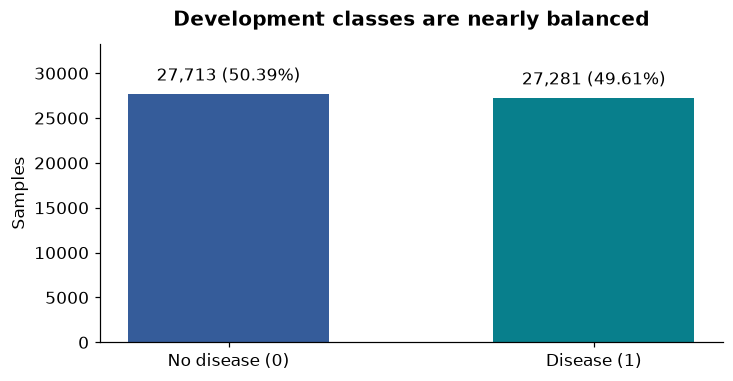

,min,25%,50%,75%,max
age,"10,859.00","17,665.00","19,701.00","21,328.00","23,713.00"
height,55.00,159.00,165.00,170.00,207.00
weight,11.00,65.00,72.00,82.00,200.00
ap_hi,16.00,120.00,120.00,140.00,"14,020.00"
ap_lo,1.00,80.00,80.00,90.00,180.00


Development age range: 29.73–64.92 years.
Five-fold majority-class baseline accuracy: 50.39%; constant-score ROC-AUC: 0.50.


In [5]:
class_counts = y_train.value_counts().reindex([0, 1])
fig, ax = plt.subplots(figsize=(6.8, 3.6))
bars = ax.bar(["No disease (0)", "Disease (1)"], class_counts, color=[BLUE, TEAL], width=0.55)
ax.bar_label(bars, labels=[f"{n:,} ({n / len(y_train):.2%})" for n in class_counts], padding=6)
ax.set(title="Development classes are nearly balanced", ylabel="Samples", ylim=(0, class_counts.max() * 1.2))
fig.tight_layout()
fig.savefig(outputs / "class_balance.png", bbox_inches="tight")
plt.show()
numeric_summary = X_train[["age", "height", "weight", "ap_hi", "ap_lo"]].describe().T
show_table(numeric_summary[["min", "25%", "50%", "75%", "max"]], {col: "{:,.2f}" for col in ["min", "25%", "50%", "75%", "max"]})
print(f"Development age range: {train_df.age.min() / 365.25:.2f}–{train_df.age.max() / 365.25:.2f} years.")
print(f"Five-fold majority-class baseline accuracy: {pd.DataFrame(majority_rows).Accuracy.mean():.2%}; constant-score ROC-AUC: 0.50.")

## 6. Outlier treatment

Three approaches were evaluated: retain extreme values, delete flagged training rows, and cap values at training-derived IQR boundaries. In the deletion experiment, validation rows were retained so that removing difficult validation samples could not artificially simplify evaluation.

The selected approach **retains rows and clips four inputs**: height, weight, systolic pressure and diastolic pressure. Age and categorical inputs are not clipped.

For each numeric input:

$$IQR = Q_3 - Q_1, \qquad L = Q_1 - 1.5IQR, \qquad U = Q_3 + 1.5IQR$$

Values below $L$ become $L$, and values above $U$ become $U$. These are **statistical boundaries**, not medical definitions of normality.

In [6]:
outlier_columns = ["height", "weight", "ap_hi", "ap_lo"]
q1, q3 = X_train[outlier_columns].quantile(0.25), X_train[outlier_columns].quantile(0.75)
lower_bounds, upper_bounds = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
X_train_clipped, X_test_clipped = X_train.copy(), X_test.copy()
boundary_table = pd.DataFrame({"Q1": q1, "Q3": q3, "Lower bound": lower_bounds, "Upper bound": upper_bounds})
for col in outlier_columns:
    boundary_table.loc[col, "Development values capped"] = int(((X_train[col] < lower_bounds[col]) | (X_train[col] > upper_bounds[col])).sum())
    X_train_clipped[col] = X_train[col].clip(lower_bounds[col], upper_bounds[col]).astype(float)
    X_test_clipped[col] = X_test[col].clip(lower_bounds[col], upper_bounds[col]).astype(float)
show_table(boundary_table, {col: "{:,.1f}" for col in boundary_table.columns})
assert len(X_train_clipped) == len(X_train) and len(X_test_clipped) == len(X_test)
boundary_table.to_csv(outputs / "clipping_boundaries.csv")
outlier_comparison = read_asset_csv(assets / "experiments/clip_outliers/comparison_results.csv")
outlier_comparison = outlier_comparison.loc[outlier_comparison.Model == "Histogram gradient boosting"].set_index("Version")
show_table(outlier_comparison[["Accuracy", "ROC-AUC", "Disease recall", "No-disease recall"]],
    {"Accuracy": "{:.2%}", "ROC-AUC": "{:.5f}", "Disease recall": "{:.2%}", "No-disease recall": "{:.2%}"},
    "Initial gradient boosting settings: five-fold validation")

,Q1,Q3,Lower bound,Upper bound,Development values capped
height,159.0,170.0,142.5,186.5,404.0
weight,65.0,82.0,39.5,107.5,"1,399.0"
ap_hi,120.0,140.0,90.0,170.0,839.0
ap_lo,80.0,90.0,65.0,105.0,"2,798.0"


,Accuracy,ROC-AUC,Disease recall,No-disease recall
Version,,,,
Clip outlier values,73.43%,0.79886,69.12%,77.68%
Delete outlier rows,73.27%,0.79791,69.09%,77.39%
Keep outliers,73.44%,0.79884,69.11%,77.71%


The initial keep-versus-clip scores were nearly identical; clipping was not selected because of a large accuracy gain. A later comparison with the **tuned** settings also found only small differences, with IQR clipping having the highest mean ROC-AUC. This supports retaining the existing treatment rather than claiming that it is statistically superior.

In [7]:
tuned_outliers = read_asset_csv(assets / "experiments/tuned_outlier_comparison/comparison_results.csv").set_index("Treatment")
show_table(tuned_outliers[["Accuracy_mean", "ROC-AUC_mean"]].rename(columns={"Accuracy_mean": "Accuracy", "ROC-AUC_mean": "ROC-AUC"}),
    {"Accuracy": "{:.2%}", "ROC-AUC": "{:.5f}"}, "Tuned gradient boosting held fixed: five-fold validation")

,Accuracy,ROC-AUC
Treatment,,
IQR clipping,73.43%,0.80035
Percentile 1-99 clipping,73.40%,0.80025
No clipping,73.39%,0.80014


## 7. Model comparison and tuning

Four retained model families were compared on the same original development folds. Logistic regression used standardized numeric inputs and one-hot categorical encoding; random forest and histogram gradient boosting used the recorded input values; CatBoost handled the six categorical inputs natively. Each approach used fold-specific clipping.

The table reports the configuration with the highest mean validation ROC-AUC **within each retained search**. Search budgets differed, so this is an experimental comparison rather than proof that one algorithm is universally better. The selected histogram gradient boosting model led CatBoost by only about **0.00013 ROC-AUC**.

The primary ranking metric was ROC-AUC. Accuracy, both recalls, precision and macro F1 were reviewed alongside it. No threshold adjustment can increase ROC-AUC when the probabilities remain unchanged.

,Configurations,Accuracy,ROC-AUC,ROC-AUC fold SD,Macro F1,Disease recall,No-disease recall
Model,,,,,,,
Histogram gradient boosting,12,73.43%,0.80035,0.00260,73.36%,68.86%,77.92%
CatBoost,12,73.33%,0.80022,0.00271,73.26%,68.66%,77.93%
Random forest,12,73.36%,0.79939,0.00229,73.29%,68.65%,78.00%
Logistic regression,6,72.85%,0.79080,0.00346,72.74%,66.85%,78.77%


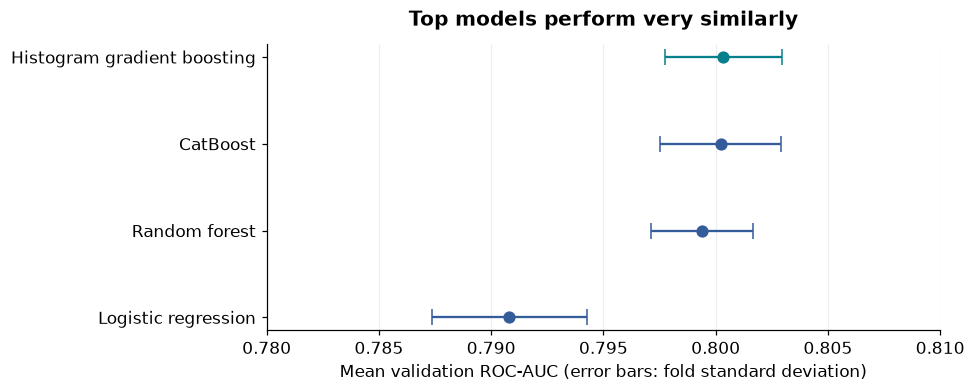

In [8]:
search_files = {
    "Logistic regression": "tune_logistic_regression", "Random forest": "tune_random_forest",
    "CatBoost": "tune_catboost", "Histogram gradient boosting": "tune_gradient_boosting"}
comparison_rows, search_evidence = [], {}
for model_name, folder in search_files.items():
    search = read_asset_csv(assets / f"experiments/{folder}/tuning_results.csv")
    best = search.sort_values("ROC-AUC_mean", ascending=False).iloc[0]
    search_evidence[model_name] = search
    comparison_rows.append({"Model": model_name, "Configurations": len(search),
        "Accuracy": best.Accuracy_mean, "ROC-AUC": best["ROC-AUC_mean"],
        "ROC-AUC fold SD": best["ROC-AUC_std"], "Macro F1": best["Macro F1_mean"],
        "Disease recall": best["Disease recall_mean"], "No-disease recall": best["No-disease recall_mean"]})
model_comparison = pd.DataFrame(comparison_rows).set_index("Model").sort_values("ROC-AUC", ascending=False)
show_table(model_comparison, {"Configurations": "{:d}", "Accuracy": "{:.2%}", "ROC-AUC": "{:.5f}",
    "ROC-AUC fold SD": "{:.5f}", "Macro F1": "{:.2%}", "Disease recall": "{:.2%}", "No-disease recall": "{:.2%}"})
model_comparison.to_csv(outputs / "model_comparison.csv")
fig, ax = plt.subplots(figsize=(9, 3.7))
ordered = model_comparison.sort_values("ROC-AUC")
for position, (name, row) in enumerate(ordered.iterrows()):
    ax.errorbar(row["ROC-AUC"], position, xerr=row["ROC-AUC fold SD"], fmt="o", capsize=5,
                color=TEAL if name == "Histogram gradient boosting" else BLUE, markersize=7)
ax.set_yticks(range(len(ordered)), ordered.index)
ax.set(xlabel="Mean validation ROC-AUC (error bars: fold standard deviation)", title="Top models perform very similarly", xlim=(0.78, 0.81))
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(outputs / "model_comparison.png", bbox_inches="tight")
plt.show()

### Selected settings and training logic

The retained gradient boosting search tested **12 combinations**: learning rate 0.03 or 0.10, 100/200/300 iterations, and 15 or 31 maximum leaves. The selected configuration was **200 iterations, learning rate 0.03, and 15 leaves**, with a minimum of 20 samples per leaf.

#### How gradient boosting works

The classifier starts with a simple prediction, then adds small decision trees in sequence. Each new tree learns adjustments that reduce the current prediction error. The learning rate controls how strongly each tree changes the combined prediction. For binary classification, the combined result is converted into a disease probability; threshold 0.50 then determines the final class.

The histogram implementation groups numeric values into bins when searching for tree splits. This reduces the number of candidate split points that must be evaluated. Its learned state consists of tree structures and leaf values. Numeric standardization is not part of this tree pipeline.

#### What tuning changed

Both rows below use the **same five development-validation folds, IQR clipping and threshold 0.50**. These are validation results, not test scores.

| Configuration | Iterations | Learning rate | Maximum leaves | Validation accuracy | Validation ROC-AUC | Disease recall | No-disease recall |
|:--|--:|--:|--:|--:|--:|--:|--:|
| Initial settings | 100 | 0.10 | 31 | 73.43% | 0.79886 | **69.12%** | 77.68% |
| Selected settings | 200 | 0.03 | 15 | 73.43% | **0.80035** | 68.86% | **77.92%** |

Tuning increased mean validation ROC-AUC by **0.00148**, while both accuracy values round to 73.43%. The selected settings were chosen for the higher mean ROC-AUC; the difference is modest and does not establish statistical superiority.

At the fixed threshold of 0.50, disease recall decreased slightly from **69.12% to 68.86%**, while no-disease recall increased from **77.68% to 77.92%**. The tuned model therefore detected slightly fewer disease cases but produced fewer false alarms on these validation folds. It was selected for its higher mean ROC-AUC, not because every metric improved. The later **69.66% disease recall is a test-set score**, so it should not be compared directly with the pre-tuning validation recall.

The code below includes the full selected-model training step. By default, it restores the preserved trained artifact. The saved clipping boundaries and feature order must match the reconstructed training pipeline.


In [9]:
metadata = json.loads((assets / "final_evaluation/evaluation_metadata.json").read_text(encoding="utf-8"))
parameters, threshold = metadata["parameters"], 0.50
bundle_path = assets / "final_evaluation/model_with_clipping.joblib"
bundle = joblib.load(bundle_path)
assert bundle["feature_columns"] == feature_columns and bundle["outlier_columns"] == outlier_columns
assert bundle["threshold"] == threshold == 0.50
assert np.allclose(bundle["lower_bounds"].loc[outlier_columns], lower_bounds.loc[outlier_columns])
assert np.allclose(bundle["upper_bounds"].loc[outlier_columns], upper_bounds.loc[outlier_columns])
for key, value in parameters.items():
    assert bundle["model"].get_params()[key] == value
if RETRAIN_MODEL:
    final_model = HistGradientBoostingClassifier(**parameters)
    final_model.fit(X_train_clipped, y_train)
    reproduced_bundle = dict(bundle, model=final_model)
    joblib.dump(reproduced_bundle, outputs / "retrained_model_with_clipping.joblib")
    print("New model trained and saved only in report/outputs.")
else:
    final_model = bundle["model"]
    print("Loaded the preserved model trained on all 54,994 development samples; no retraining.")
show_table(pd.DataFrame({"Value": {**parameters, "threshold": threshold}}))

Loaded the preserved model trained on all 54,994 development samples; no retraining.


,Value
max_iter,200
learning_rate,0.030000
max_leaf_nodes,15
min_samples_leaf,20
early_stopping,False
random_state,42
threshold,0.500000


## 8. Recorded test evaluation

The selected classifier is evaluated on the **13,748 reserved records**, using boundaries learned from development data. The following cell reproduces the saved probabilities and metrics, rather than choosing settings from these results.

`predict_proba(... )[:, 1]` returns the probability assigned to class 1. The prediction is disease when that probability is **at least 0.50**. Metrics expressed as percentages below are proportions multiplied by 100; ROC-AUC remains on its 0–1 scale.

In [10]:
probabilities = final_model.predict_proba(X_test_clipped)[:, 1]
predictions = (probabilities >= threshold).astype(int)
test_scores = pd.Series({
    "Accuracy": accuracy_score(y_test, predictions),
    "Balanced accuracy": balanced_accuracy_score(y_test, predictions),
    "ROC-AUC": roc_auc_score(y_test, probabilities),
    "Macro F1": f1_score(y_test, predictions, average="macro"),
    "Disease recall": recall_score(y_test, predictions, pos_label=1),
    "No-disease recall": recall_score(y_test, predictions, pos_label=0),
    "Disease precision": precision_score(y_test, predictions, pos_label=1, zero_division=0),
    "No-disease precision": precision_score(y_test, predictions, pos_label=0, zero_division=0),
}, name="Test score")
recorded_scores = read_asset_csv(assets / "final_evaluation/test_metrics.csv", index_col=0)["Test score"]
recorded_predictions = read_asset_csv(assets / "final_evaluation/test_predictions.csv").set_index("id").loc[test_df.id]
assert np.array_equal(recorded_predictions["Actual disease"].to_numpy(), y_test.to_numpy())
assert np.allclose(probabilities, recorded_predictions["Disease probability"].to_numpy(), rtol=0, atol=1e-12)
assert np.allclose(test_scores, recorded_scores.loc[test_scores.index], rtol=0, atol=1e-12)
score_display = test_scores.to_frame()
score_display["Displayed result"] = [f"{value:.4f}" if name == "ROC-AUC" else f"{value:.2%}" for name, value in test_scores.items()]
show_table(score_display[["Displayed result"]])
matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
assert matrix.tolist() == [[5462, 1552], [2043, 4691]]
test_scores.to_csv(outputs / "test_metrics.csv")
classification = pd.DataFrame(classification_report(y_test, predictions, labels=[0, 1],
    target_names=["No disease", "Disease"], output_dict=True, zero_division=0)).T
show_table(classification.loc[["No disease", "Disease", "macro avg", "weighted avg"]],
    {"precision": "{:.2%}", "recall": "{:.2%}", "f1-score": "{:.2%}", "support": "{:,.0f}"})

,Displayed result
Accuracy,73.85%
Balanced accuracy,73.77%
ROC-AUC,0.8051
Macro F1,73.77%
Disease recall,69.66%
No-disease recall,77.87%
Disease precision,75.14%
No-disease precision,72.78%


,precision,recall,f1-score,support
No disease,72.78%,77.87%,75.24%,"7,014"
Disease,75.14%,69.66%,72.30%,"6,734"
macro avg,73.96%,73.77%,73.77%,"13,748"
weighted avg,73.94%,73.85%,73.80%,"13,748"


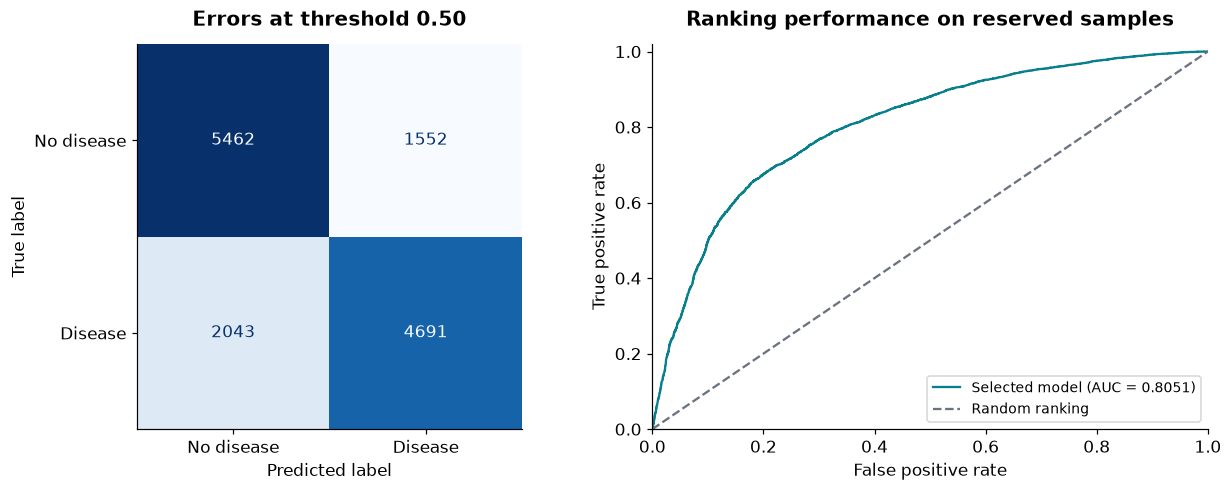

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.6))
ConfusionMatrixDisplay(matrix, display_labels=["No disease", "Disease"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
axes[0].set_title("Errors at threshold 0.50")
false_positive_rate, true_positive_rate, _ = roc_curve(y_test, probabilities)
axes[1].plot(false_positive_rate, true_positive_rate, color=TEAL,
    label=f"Selected model (AUC = {test_scores['ROC-AUC']:.4f})")
axes[1].plot([0, 1], [0, 1], "--", color=GREY, label="Random ranking")
axes[1].set(xlabel="False positive rate", ylabel="True positive rate", xlim=(0, 1), ylim=(0, 1.02))
axes[1].legend(loc="lower right", fontsize=9)
axes[1].set_title("Ranking performance on reserved samples")
fig.tight_layout()
fig.savefig(outputs / "test_confusion_and_roc.png", bbox_inches="tight")
plt.show()

### Interpreting the result

The model correctly identifies **4,691 disease cases** and **5,462 no-disease cases**. It misses **2,043 disease cases** and produces **1,552 false alarms**.

| Metric | Meaning for this project |
|:--|:--|
| Disease recall / sensitivity | Of 100 actual disease cases, about **70** are detected. |
| No-disease recall / specificity | Of 100 actual no-disease cases, about **78** are correctly rejected. |
| Disease precision | Of 100 disease predictions, about **75** match the disease label. |
| Balanced accuracy / macro recall | Equal average of disease and no-disease recall: **73.77%**. |
| Macro F1 | Equal average of the two class F1 scores: **73.77%** after rounding. |
| ROC-AUC | Measures probability ranking across thresholds, not accuracy at 0.50. |

Balanced accuracy and macro F1 happen to round to the same percentage; they are different metrics. A useful dataset classifier can still miss many disease cases, so these results do not justify clinical screening use.

## 9. Decision threshold experiments

The classifier is trained before choosing a cutoff. Changing a threshold changes the binary decisions, not the learned trees or their probability ranking. The development experiment compared thresholds from 0.20 through 0.80 in increments of 0.01.

Lowering the threshold increases disease detection at the cost of more false alarms. Among the tested grid values, 0.50 had the highest mean validation accuracy; 0.48 had the highest macro F1 by a very small margin; 0.45 produced the closest class recalls. These are exploratory selections on the same development predictions, not independently confirmed optima.

,Accuracy,Macro F1,Disease recall,No-disease recall,Disease precision,ROC-AUC
Threshold,,,,,,
0.500000,73.43%,73.36%,68.86%,77.92%,75.43%,0.80035
0.480000,73.40%,73.37%,70.97%,75.78%,74.26%,0.80035
0.450000,73.21%,73.21%,73.63%,72.80%,72.71%,0.80035
0.400000,72.42%,72.35%,78.22%,66.72%,69.82%,0.80035


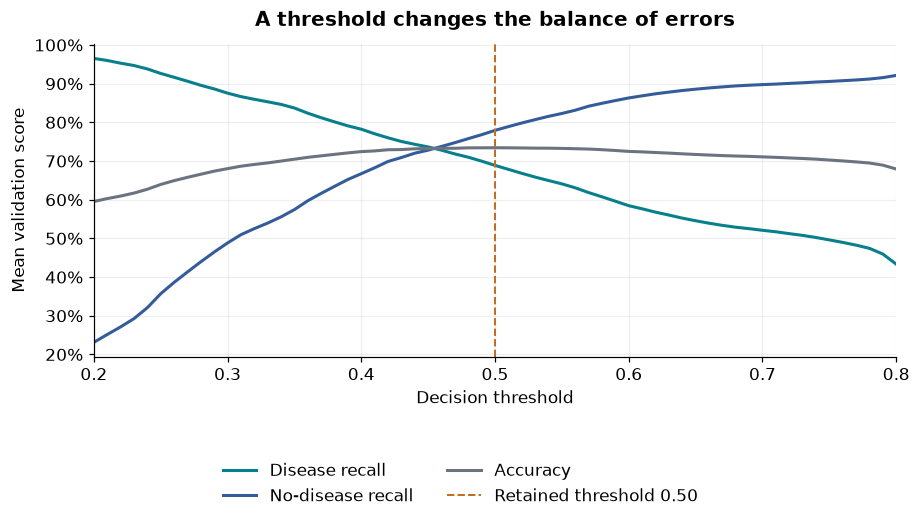

In [12]:
threshold_results = read_asset_csv(assets / "experiments/threshold_comparison/threshold_summary.csv").set_index("Threshold")
threshold_table = threshold_results.loc[[0.50, 0.48, 0.45, 0.40], ["Accuracy", "Macro F1", "Disease recall", "No-disease recall", "Disease precision", "ROC-AUC"]]
show_table(threshold_table, {col: "{:.5f}" if col == "ROC-AUC" else "{:.2%}" for col in threshold_table},
    "Five-fold development validation; same probabilities at every threshold")
assert np.allclose(threshold_results["ROC-AUC"], threshold_results["ROC-AUC"].iloc[0])
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for metric, color in [("Disease recall", TEAL), ("No-disease recall", BLUE), ("Accuracy", GREY)]:
    ax.plot(threshold_results.index, threshold_results[metric], label=metric, color=color, linewidth=2)
ax.axvline(0.50, color=ORANGE, linestyle="--", linewidth=1.3, label="Retained threshold 0.50")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(xlabel="Decision threshold", ylabel="Mean validation score", title="A threshold changes the balance of errors", xlim=(0.2, 0.8))
ax.grid(alpha=0.2)
fig.legend(*ax.get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, 0.0), ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0.18, 1, 1))
fig.savefig(outputs / "threshold_tradeoffs.png", bbox_inches="tight")
plt.show()

### Additional test comparison and retained decision

The fixed 0.48 threshold was later evaluated on the same reserved records. It detected **101 additional disease cases**, but introduced **150 additional false alarms**. Accuracy decreased from **73.85% to 73.49%**. This later test comparison is disclosed because it means the test set is no longer untouched for the overall project.

The final configuration remains **0.50**, reflecting the chosen accuracy/false-alarm trade-off. A different clinical or operational objective could justify another threshold, but no cost-based objective was established here. Neither threshold is universally best.

In [13]:
threshold_test = read_asset_csv(assets / "experiments/threshold_048_stability/test_comparison.csv").set_index("Threshold")
show_table(threshold_test[["Accuracy", "Disease recall", "No-disease recall", "FP", "FN"]],
    {"Accuracy": "{:.2%}", "Disease recall": "{:.2%}", "No-disease recall": "{:.2%}", "FP": "{:,.0f}", "FN": "{:,.0f}"},
    "Previously completed additional test comparison; no threshold search is run here")

,Accuracy,Disease recall,No-disease recall,FP,FN
Threshold,,,,,
0.500000,73.85%,69.66%,77.87%,"1,552","2,043"
0.480000,73.49%,71.16%,75.73%,"1,702","1,942"


## 10. Consistency and learning curves

The selected model was retrained with the same settings across five sets of five grouped folds (split seeds 42, 7, 21, 84 and 123). Each arrangement validates every development sample once. The original arrangement was used during selection; four alternative arrangements assess sensitivity to the split.

Across those four alternatives, mean accuracy ranged from **73.37% to 73.45%**. This is evidence that average performance is stable under these fold assignments. It is not a guarantee for another hospital, population or future dataset. Repeats share records, so their standard deviation is descriptive rather than an independent confidence interval.

,Accuracy,ROC-AUC,Disease recall,No-disease recall
Split seed,,,,
42,73.43%,0.80035,68.86%,77.92%
7,73.43%,0.80029,68.79%,78.00%
21,73.45%,0.79986,68.94%,77.89%
84,73.37%,0.80018,68.84%,77.84%
123,73.44%,0.80036,68.78%,78.02%


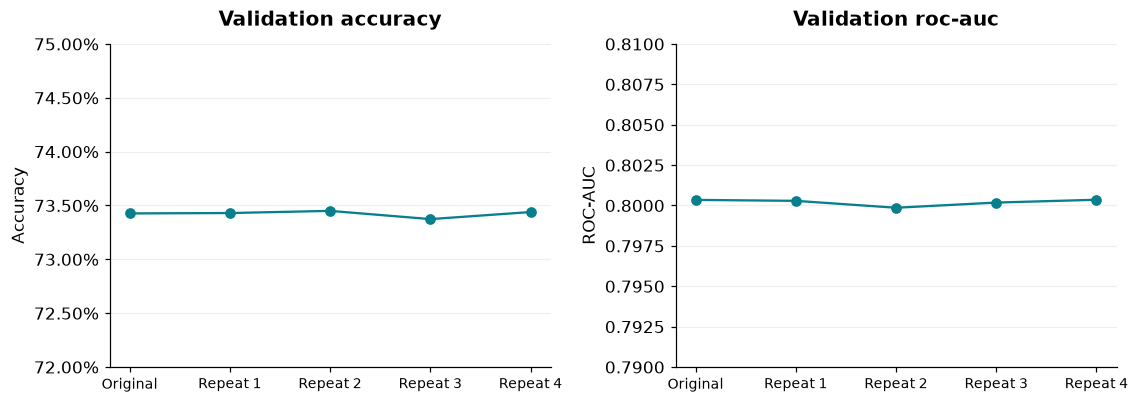

In [14]:
stability_folds = read_asset_csv(assets / "experiments/split_stability/validation_folds.csv")
stability_means = stability_folds.groupby("Split seed")[["Accuracy", "ROC-AUC", "Disease recall", "No-disease recall"]].mean().reindex([42, 7, 21, 84, 123])
show_table(stability_means, {col: "{:.5f}" if col == "ROC-AUC" else "{:.2%}" for col in stability_means})
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
labels = ["Original", "Repeat 1", "Repeat 2", "Repeat 3", "Repeat 4"]
for ax, metric in zip(axes, ["Accuracy", "ROC-AUC"]):
    ax.plot(labels, stability_means[metric], "o-", color=TEAL)
    ax.set(title=f"Validation {metric.lower()}", ylabel=metric)
    ax.grid(axis="y", alpha=0.2)
    ax.tick_params(axis="x", labelsize=9)
axes[0].set_ylim(0.72, 0.75)
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_ylim(0.79, 0.81)
fig.tight_layout()
fig.savefig(outputs / "split_stability.png", bbox_inches="tight")
plt.show()

A separate learning-curve experiment held the tuned settings fixed and varied the training subset size within each fold. Approximately 4,400 fitting samples gave **72.76%** validation accuracy, compared with **73.43%** for approximately 44,000. The diminishing gains suggest that more records alone may yield limited improvement for this fixed model, but do not establish the dataset's maximum achievable score.

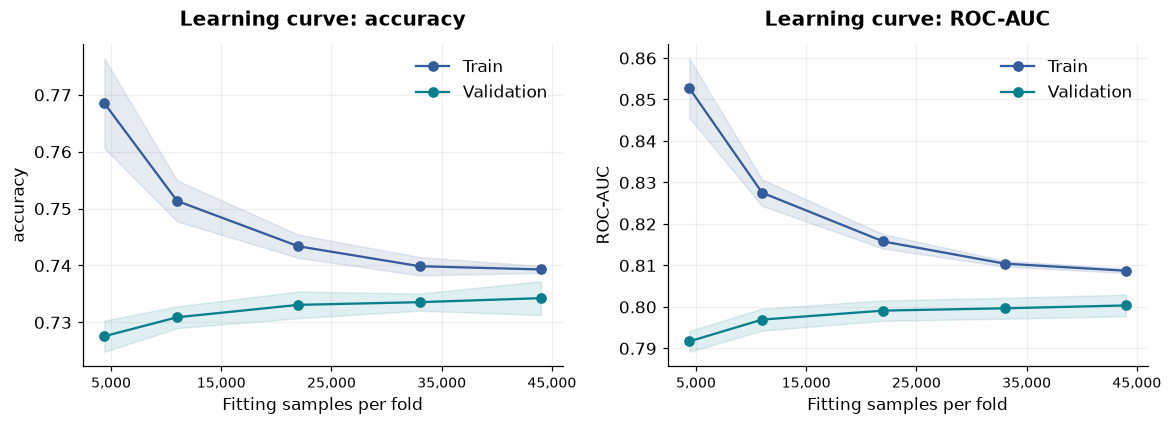

Shading shows fold standard deviation. The largest subset leaves a validation fold out of fitting.


In [15]:
learning = read_asset_csv(assets / "experiments/learning_curve/learning_curve_summary.csv")
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4))
for ax, metric in zip(axes, ["accuracy", "ROC-AUC"]):
    for split, color in [("Train", BLUE), ("Validation", TEAL)]:
        mean = learning[f"{split} {metric}_mean"].to_numpy()
        std = learning[f"{split} {metric}_std"].to_numpy()
        sizes = learning["Training rows_mean"].to_numpy()
        ax.plot(sizes, mean, "o-", label=split, color=color)
        ax.fill_between(sizes, mean - std, mean + std, alpha=0.12, color=color)
    ax.set(xlabel="Fitting samples per fold", ylabel=metric, title=f"Learning curve: {metric}")
    ax.set_xticks([5000, 15000, 25000, 35000, 45000], ["5,000", "15,000", "25,000", "35,000", "45,000"], fontsize=9)
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(outputs / "learning_curve.png", bbox_inches="tight")
plt.show()
print("Shading shows fold standard deviation. The largest subset leaves a validation fold out of fitting.")

## 11. Where errors occur

The saved out-of-fold error analysis examined raw measurements, without deleting rows or changing labels. Development samples with systolic pressure in **[120, 140)** had an error rate of **33.31%**. At systolic pressure **140 or above**, the model classified almost everyone as having disease, failing to identify the no-disease cases in those descriptive groups.

These intervals describe the analysis; they are not proposed diagnostic or cleaning thresholds. Associations do not establish a cause, and a wrong prediction is not evidence that the dataset label is wrong.

Rows flagged by at least one IQR rule had a lower error rate (**22.20%**) than unflagged rows (**27.01%**). This does not support deleting more outliers simply to increase performance.

In [16]:
subgroups = read_asset_csv(assets / "experiments/error_analysis/subgroup_errors.csv")
pressure_errors = subgroups.loc[subgroups.Dimension == "Systolic group", ["Group", "Samples", "Errors", "Error rate", "Disease recall", "No-disease recall"]].set_index("Group")
show_table(pressure_errors, {"Samples": "{:,.0f}", "Errors": "{:,.0f}", "Error rate": "{:.2%}",
    "Disease recall": "{:.2%}", "No-disease recall": "{:.2%}"}, "Exploratory development error analysis; overlapping covariates")

,Samples,Errors,Error rate,Disease recall,No-disease recall
Group,,,,,
"[0.0, 100.0)",840,120,14.29%,8.06%,99.16%
"[100.0, 120.0)","9,351","2,129",22.77%,16.61%,96.53%
"[120.0, 140.0)","29,995","9,992",33.31%,47.88%,80.06%
"[140.0, 160.0)","11,160","1,867",16.73%,99.99%,0.00%
"[160.0, 180.0)","2,905",403,13.87%,100.00%,0.00%
"[180.0, inf)",743,103,13.86%,100.00%,0.00%


## 12. Conclusions and limitations

The selected histogram gradient boosting pipeline achieved **73.85% recorded test accuracy** and **0.8051 ROC-AUC**. Its validation performance was stable across the tested fold arrangements. It improved substantially over a majority-class baseline, while the top tree models performed similarly to one another.

The final approach excludes pressure-inconsistent records, groups exact input matches, learns IQR caps within training data, and uses threshold 0.50. It is a reproducible solution to the course classification task.

Important limits remain:

1. **Missed cases:** disease recall is 69.66%; 2,043 of 6,734 test disease cases are missed.
2. **Scope:** evaluation excludes pressure-inconsistent records and uses one supplied dataset whose collection and label rules are not independently verified.
3. **Selection uncertainty:** many development comparisons reuse records and folds. Small gains should not be presented as proven algorithmic superiority.
4. **Test history:** the reserved set has been examined at 0.50 and later at 0.48; this report does not claim an untouched final confirmation after every subsequent experiment.
5. **Deployment:** no external validation or probability-calibration study establishes clinical use. More tuning cannot be assumed to produce a large improvement.

Further work would require a defined decision cost, careful validation under that objective, and ideally independent data. Within this project's constraints, the retained model provides a defensible result with explicitly reported weaknesses.

In [17]:
for item in source_manifest:
    assert hashlib.sha256((assets / item["path"]).read_bytes()).hexdigest() == item["sha256"]
audit = {
    "dataset_rows": len(df), "pressure_valid_rows": len(pressure_valid),
    "development_rows": len(train_df), "test_rows": len(test_df),
    "group_separation_verified": True, "original_test_metrics_reproduced": True,
    "evidence_hashes_verified": True, "retrained_model": RETRAIN_MODEL,
    "threshold": threshold, "python": platform.python_version(), "sklearn": sklearn.__version__,
    "test_history": "Original evaluation at 0.50; later comparison at 0.48 is disclosed.",
}
(outputs / "report_checks.json").write_text(json.dumps(audit, indent=2), encoding="utf-8")
print("Report checks passed: dataset counts, group separation, preprocessing, model settings, saved probabilities and test metrics.")
print("All copied source evidence remains unchanged. Generated outputs are confined to this report folder.")

Report checks passed: dataset counts, group separation, preprocessing, model settings, saved probabilities and test metrics.
All copied source evidence remains unchanged. Generated outputs are confined to this report folder.


## Updated final decision: threshold 0.37

After the historical experiments above, 0.37 was chosen to increase disease detection. On five-fold development validation it gives **71.33% accuracy, 81.18% disease recall, 61.63% no-disease recall and 67.57% disease precision**. Against 0.50, it detects 3,360 additional disease cases but adds 4,513 false alarms across 54,994 development records. Against 0.35, it produces 1,163 fewer false alarms while missing 686 additional disease cases.

The same selected trees and IQR caps are used; only the decision cutoff changes. The following is an **additional evaluation on the previously examined 13,748-record test partition**, not independent confirmation. It gives **71.79% accuracy, 81.60% disease recall, 62.38% no-disease recall, 67.56% disease precision and ROC-AUC 0.8051**. There are 1,239 missed disease cases and 2,639 false alarms. The earlier 73.85% test accuracy applies only to threshold 0.50.

The trained model file and its original threshold metadata are retained unchanged. This cell applies 0.37 explicitly and writes only report outputs.


In [18]:
selected_threshold = 0.37
selected_predictions = (probabilities >= selected_threshold).astype(int)
selected_scores = pd.Series({
    "Accuracy": accuracy_score(y_test, selected_predictions),
    "Balanced accuracy": balanced_accuracy_score(y_test, selected_predictions),
    "ROC-AUC": roc_auc_score(y_test, probabilities),
    "Macro F1": f1_score(y_test, selected_predictions, average="macro"),
    "Disease recall": recall_score(y_test, selected_predictions, pos_label=1),
    "No-disease recall": recall_score(y_test, selected_predictions, pos_label=0),
    "Disease precision": precision_score(y_test, selected_predictions, pos_label=1, zero_division=0),
    "No-disease precision": precision_score(y_test, selected_predictions, pos_label=0, zero_division=0),
}, name="Test score at threshold 0.37")
selected_matrix = confusion_matrix(y_test, selected_predictions, labels=[0, 1])
assert selected_matrix.tolist() == [[4375, 2639], [1239, 5495]]
print("Selected decision threshold: 0.37")
for metric, value in selected_scores.items():
    formatted = f"{value:.4f}" if metric == "ROC-AUC" else f"{value:.2%}"
    print(f"{metric}: {formatted}")
print("Confusion matrix (actual rows, predicted columns; class order 0, 1):")
print(selected_matrix)
selected_scores.to_csv(outputs / "threshold_037_test_metrics.csv")


Selected decision threshold: 0.37
Accuracy: 71.79%
Balanced accuracy: 71.99%
ROC-AUC: 0.8051
Macro F1: 71.60%
Disease recall: 81.60%
No-disease recall: 62.38%
Disease precision: 67.56%
No-disease precision: 77.93%
Confusion matrix (actual rows, predicted columns; class order 0, 1):
[[4375 2639]
 [1239 5495]]
